<a href="https://www.kaggle.com/code/yonasyifter/quantum-dynamics-1?scriptVersionId=368442794" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Forecasting quantum many-body dynamics: linear models vs Transformers

**Deep Learning project (A.Y. 2026/2027) - "Quantum Dynamics" track**

This notebook follows the roadmap of the project guidelines (Step 0 -> Step 3) and the protocol of the reference paper *"The surprising simplicity of forecasting quantum chaotic many-body dynamics"* (Perciavalle, Gallo et al., arXiv:2610.10697), adapted to the dataset provided for the course.

## Step 0 - Context and objective

**Physical system.** A chain of `N = 10` interacting atoms (qubits) driven by a laser. Every simulation ("trajectory") starts from the same initial state and differs only in two laser parameters: the amplitude `Omega` and the detuning `Delta`. At each sampled time we are given `N` local magnetizations `m_j(t)` and `N(N-1)/2` connected correlations `c_ij(t)`, i.e. `F = N(N+1)/2 = 55` features.

**Why machine learning.** Exact simulation costs grow as `2^N`, and approximate (tensor-network) methods only reach short times. The question is whether the *late-time* dynamics of the observables can be forecast from the *early-time* dynamics, without propagating the quantum state.

**Learning problem.** Multivariate time-series forecasting. For each trajectory `k`:

- input: the first `rho = N_points_train` time steps, `X_in in R^(rho x F)`
- target: the remaining `tau = N_points - rho` time steps, `X_out in R^(tau x F)`

and we learn `f: R^(rho x F) -> R^(tau x F)`. The data are split along two directions, as requested by the README: by **trajectory** (the test pairs `(Omega, Delta)` are never seen in training) and by **time** (the model must predict later times).

**Tasks addressed** (from the list in the slides / README):

1. Transformer vs linear model (DLinear), plus two naive baselines as a sanity floor.
2. How the error depends on `(Omega, Delta)`.
3. How the error changes with the number of training time steps `N_points_train`.
4. How the error changes with the number of training trajectories `N_traj_train`.

**How the guideline rules are implemented**

| Rule | Where |
|---|---|
| Never trust the data | Section 2: automated consistency report |
| Conventional pipeline, explore hyperparameters, cross-validate | Sections 7-8: K-fold CV over 3 configurations per model |
| Mean always with 95% confidence interval, best in bold | `mean_ci`, Table 1 and all result tables |
| Metrics per variable group | every metric is reported for magnetizations and correlations separately |
| Reproducibility | one global seed, `seed_everything`, seeded splits and loaders |
| Plots as JPEG, at least 300 dpi | `save_fig` |
| Computational cost must be quantified | Section 7.1 measures seconds per epoch and projects the budget |
| No pretrained models | everything is trained from scratch |

**Notebook layout.** Sections 1-6 only *define* things (configuration, data, models, loss, metrics, trainer). Sections 7-12 *run* experiments, and every experiment goes through one single function, `run_experiment`, so that all studies share exactly the same pipeline.

## 1. Setup

### 1.1 Imports

Standard scientific stack plus TensorFlow / Keras, the framework used in the labs. Only standard Keras building blocks are used: `Dense`, `MultiHeadAttention`, `LayerNormalization`, `Dropout`, `AveragePooling1D`, the functional API, `model.compile` / `model.fit` and the usual callbacks.

In [20]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"        # hide TensorFlow C++ log lines

import copy
import gc
import json
import math
import pickle
import time
import warnings
from dataclasses import dataclass, asdict
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.signal import savgol_filter

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.get_logger().setLevel("ERROR")

from IPython.display import display, HTML

print("numpy", np.__version__, "| pandas", pd.__version__, "| tensorflow", tf.__version__, "| keras", keras.__version__)

numpy 2.1.3 | pandas 2.3.3 | tensorflow 2.21.0 | keras 3.13.2


### 1.2 Configuration

All knobs of the notebook live in one `Config` object, so nothing is hard-coded further down.

- `PROFILE` selects the computational budget. `"fast"` is a smoke test that runs the whole notebook in a few minutes (results are meaningless), `"standard"` is the intended setting, `"full"` uses more folds and seeds.
- `rho` is the default number of training time steps (`N_points_train`). With 501 points and `dt = 0.01`, `rho = 300` means: observe `t in [0, 3)`, predict `t in [3, 5]`.
- The test set is 20% of the trajectories (100 of 500) and is the same in every experiment.

In [21]:
PROFILE = "standard"          # "fast" | "standard" | "full"


@dataclass
class Config:
    # ---- data ----
    data_dir: str = "/kaggle/input/datasets/yonasyifter/quantum-dynamics/dataN10/dataN10"
    params_file: str = "parameters_ed.csv"
    traj_file: str = "trajectories_ed.csv"
    out_dir: str = "/kaggle/working/outputs"
    max_trajectories: Optional[int] = None      # debug only: keep the first n trajectories

    # ---- problem definition ----
    rho: int = 300                # N_points_train: number of input time steps
    test_fraction: float = 0.2    # fraction of trajectories held out for the final test
    val_fraction: float = 0.2     # fraction of the training trajectories used for early stopping

    # ---- protocol ----
    seed: int = 42
    deterministic_ops: bool = True   # ask TensorFlow for deterministic GPU kernels (slower, reproducible)
    cv_folds: int = 3
    final_seeds: Tuple[int, ...] = (0, 1, 2)
    study_seeds: Tuple[int, ...] = (0, 1, 2)
    study_models: Tuple[str, ...] = ("dlinear", "transformer")
    study_rhos: Tuple[int, ...] = (100, 200, 300, 400)
    study_ntrain: Tuple[int, ...] = (25, 50, 100, 200, 400)
    epoch_scale: float = 1.0      # multiplies max_epochs of every model

    # ---- evaluation ----
    smooth_windows: Tuple[int, ...] = (11, 21, 41)   # Savitzky-Golay windows (time steps, odd)
    conf_level: float = 0.95


def apply_profile(cfg: Config, profile: str) -> Config:
    """Adapt the computational budget. Only protocol sizes change, never the pipeline."""
    if profile == "fast":
        cfg.cv_folds = 2
        cfg.final_seeds = (0, 1)
        cfg.study_seeds = (0, 1)
        cfg.study_rhos = (200, 300)
        cfg.study_ntrain = (25, 100)
        cfg.epoch_scale = 0.05
    elif profile == "full":
        cfg.cv_folds = 5
        cfg.final_seeds = (0, 1, 2, 3, 4)
        cfg.study_seeds = (0, 1, 2, 3, 4)
    elif profile != "standard":
        raise ValueError(f"unknown profile {profile!r}")
    return cfg


CFG = apply_profile(Config(), PROFILE)
if not Path(CFG.out_dir).parent.exists():      # not on Kaggle: write next to the notebook
    CFG.out_dir = "outputs"

FIG_DIR = Path(CFG.out_dir) / "figures"
TAB_DIR = Path(CFG.out_dir) / "tables"
for d in (FIG_DIR, TAB_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(json.dumps(asdict(CFG), indent=2))

{
  "data_dir": "/kaggle/input/datasets/yonasyifter/quantum-dynamics/dataN10/dataN10",
  "params_file": "parameters_ed.csv",
  "traj_file": "trajectories_ed.csv",
  "out_dir": "/kaggle/working/outputs",
  "max_trajectories": null,
  "rho": 300,
  "test_fraction": 0.2,
  "val_fraction": 0.2,
  "seed": 42,
  "deterministic_ops": true,
  "cv_folds": 3,
  "final_seeds": [
    0,
    1,
    2
  ],
  "study_seeds": [
    0,
    1,
    2
  ],
  "study_models": [
    "dlinear",
    "transformer"
  ],
  "study_rhos": [
    100,
    200,
    300,
    400
  ],
  "study_ntrain": [
    25,
    50,
    100,
    200,
    400
  ],
  "epoch_scale": 1.0,
  "smooth_windows": [
    11,
    21,
    41
  ],
  "conf_level": 0.95
}


### 1.3 Reproducibility and small utilities

- `seed_everything` fixes the Python, NumPy and TensorFlow generators with `keras.utils.set_random_seed`. It is called at the start of **every** training run, so a run depends only on its own seed and not on what was executed before it. With `deterministic_ops=True` TensorFlow is also asked to use deterministic GPU kernels; if a GPU operation has no deterministic version TensorFlow raises an `UnimplementedError`, and in that case set the flag to `False` (results are then reproducible only up to small GPU round-off).
- `save_fig` enforces the guideline format: JPEG, 300 dpi.
- `mean_ci` returns the mean and the half-width of the Student-t confidence interval. With few repetitions (3 folds or 3 seeds) the t-quantile is large (4.30 for n = 3), so the intervals are honest about the small sample.

In [22]:
def seed_everything(seed: int) -> None:
    os.environ["PYTHONHASHSEED"] = str(seed)
    keras.utils.set_random_seed(seed)          # python, numpy and tensorflow generators


def describe_device() -> str:
    gpus = tf.config.list_physical_devices("GPU")
    return f"GPU x{len(gpus)} ({gpus[0].name})" if gpus else "CPU"


def save_fig(fig, name: str, show: bool = True) -> Path:
    """Save a figure as JPEG at 300 dpi (project rule) and optionally display it."""
    path = FIG_DIR / f"{name}.jpeg"
    fig.savefig(path, dpi=300, format="jpeg", bbox_inches="tight")
    if show:
        plt.show()
    plt.close(fig)
    return path


def mean_ci(values, conf: float = 0.95) -> Tuple[float, float]:
    """Mean and half-width of the Student-t confidence interval."""
    v = np.asarray(values, dtype=float)
    v = v[~np.isnan(v)]
    if v.size == 0:
        return float("nan"), float("nan")
    if v.size < 2:
        return float(v.mean()), float("nan")
    half = stats.t.ppf(0.5 + conf / 2, v.size - 1) * v.std(ddof=1) / math.sqrt(v.size)
    return float(v.mean()), float(half)


def fmt_ci(values, conf: float = 0.95, digits: int = 4) -> str:
    m, h = mean_ci(values, conf)
    return f"{m:.{digits}f}" if np.isnan(h) else f"{m:.{digits}f} ± {h:.{digits}f}"


plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

if CFG.deterministic_ops:
    tf.config.experimental.enable_op_determinism()
DEVICE = describe_device()
seed_everything(CFG.seed)
print("device:", DEVICE)

device: GPU x2 (/physical_device:GPU:0)


## 2. Step 1 - Import the data and check it

### 2.1 Loading functions

The README describes the layout, but the loader does not rely on it blindly:

- the files are looked up at the configured Kaggle path, with a fallback search under `/kaggle/input` in case the folder is mounted elsewhere;
- the presence of a header row is detected from the file itself;
- trajectories are separated by detecting where the time column restarts, instead of assuming 501 rows each;
- the number of sites `N` is inferred from the number of columns (`F = N(N+1)/2`), because the README states `N = 20` in the description and `N = 10` in the data-structure section.

`FeatureSpec` stores which columns are magnetizations and which are correlations, and the pair `(i, j)` and distance `|i - j|` of each correlation. It is used later to report every metric per group.

In [23]:
@dataclass
class FeatureSpec:
    n_sites: int
    names: List[str]
    mag_idx: np.ndarray               # columns holding m_1..m_N
    corr_idx: np.ndarray              # columns holding c_ij, i<j
    pairs: List[Tuple[int, int]]      # (i, j), 0-based, for each correlation
    pair_dist: np.ndarray             # |i-j| for each correlation
    mirror_perm: np.ndarray           # feature permutation under the reflection j -> N+1-j

    @property
    def n_features(self) -> int:
        return len(self.names)

    @property
    def groups(self) -> Dict[str, np.ndarray]:
        return {"mag": self.mag_idx, "corr": self.corr_idx}


def make_feature_spec(n_features: int) -> FeatureSpec:
    n = (-1 + math.sqrt(1 + 8 * n_features)) / 2
    if abs(n - round(n)) > 1e-9:
        raise ValueError(f"{n_features} features is not N(N+1)/2 for any integer N")
    n = int(round(n))
    pairs = [(i, j) for i in range(n) for j in range(i + 1, n)]
    names = [f"m_{i + 1}" for i in range(n)] + [f"c_{i + 1},{j + 1}" for i, j in pairs]
    pair_pos = {p: n + q for q, p in enumerate(pairs)}
    mirror = [n - 1 - i for i in range(n)] + [pair_pos[(n - 1 - j, n - 1 - i)] for i, j in pairs]
    return FeatureSpec(n, names, np.arange(n), np.arange(n, n_features), pairs,
                       np.array([j - i for i, j in pairs]), np.array(mirror))


@dataclass
class QuantumData:
    time: np.ndarray          # (T,)
    X: np.ndarray             # (K, T, F) float32
    times_all: np.ndarray     # (K, T) time column of every trajectory (for validation)
    params: pd.DataFrame      # one row per trajectory
    omega: np.ndarray         # (K,)
    delta: np.ndarray         # (K,)
    spec: FeatureSpec

    @property
    def n_traj(self) -> int:
        return self.X.shape[0]

    @property
    def n_points(self) -> int:
        return self.X.shape[1]

    @property
    def dt(self) -> float:
        return float(self.time[1] - self.time[0])


def resolve_data_file(cfg: Config, filename: str) -> Path:
    path = Path(cfg.data_dir) / filename
    if path.exists():
        return path
    hits = []
    for root in (Path("/kaggle/input"), Path(".")):
        if root.exists():
            hits += sorted(root.rglob(filename))
    if not hits:
        raise FileNotFoundError(f"{filename} not found in {cfg.data_dir} nor under /kaggle/input")
    print(f"[warning] {path} not found, using {hits[0]} instead")
    return hits[0]


def _has_header(path: Path) -> bool:
    with open(path) as fh:
        first = fh.readline().strip().split(",")
    try:
        [float(v) for v in first[:3]]
        return False
    except ValueError:
        return True


def load_parameters(path: Path) -> pd.DataFrame:
    if _has_header(path):
        df = pd.read_csv(path)
        df.columns = [str(c).strip() for c in df.columns]
    else:
        df = pd.read_csv(path, header=None)
        default = ["traj_id", "Omega", "Delta", "max_bond_dim", "hit_maxdim"]
        df.columns = default[:df.shape[1]] + [f"extra_{i}" for i in range(max(0, df.shape[1] - len(default)))]
    lower = {c.lower(): c for c in df.columns}
    for wanted in ("omega", "delta"):
        if wanted not in lower:
            raise KeyError(f"column '{wanted}' not found in {path.name}: {list(df.columns)}")
    return df.rename(columns={lower["omega"]: "Omega", lower["delta"]: "Delta",
                              lower.get("traj_id", "traj_id"): "traj_id"})


def load_trajectories(path: Path) -> Tuple[np.ndarray, np.ndarray]:
    """Return (times_all (K, T), X (K, T, F)). Trajectories are split where time restarts."""
    raw = pd.read_csv(path, header=0 if _has_header(path) else None, dtype=np.float64).to_numpy()
    t = raw[:, 0]
    starts = np.flatnonzero(np.r_[True, np.diff(t) <= 0])
    lengths = np.diff(np.r_[starts, len(t)])
    if len(set(lengths.tolist())) != 1:
        raise ValueError(f"trajectories have different lengths: {sorted(set(lengths.tolist()))}")
    block = raw.reshape(len(starts), int(lengths[0]), raw.shape[1])
    return block[:, :, 0], block[:, :, 1:]


def load_dataset(cfg: Config) -> QuantumData:
    params = load_parameters(resolve_data_file(cfg, cfg.params_file))
    times_all, X = load_trajectories(resolve_data_file(cfg, cfg.traj_file))
    if len(params) != X.shape[0]:
        raise ValueError(f"{len(params)} parameter rows but {X.shape[0]} trajectories")
    if cfg.max_trajectories is not None:
        keep = slice(0, cfg.max_trajectories)
        params, times_all, X = params.iloc[keep].reset_index(drop=True), times_all[keep], X[keep]
    return QuantumData(time=times_all[0].copy(), X=X.astype(np.float32), times_all=times_all,
                       params=params, omega=params["Omega"].to_numpy(float),
                       delta=params["Delta"].to_numpy(float), spec=make_feature_spec(X.shape[2]))

### 2.2 Load

The data are stored as a single tensor `X` of shape `(N_traj, N_points, F)`, the same representation used in the paper.

In [24]:
QD = load_dataset(CFG)
SPEC = QD.spec
print(f"X: {QD.X.shape}  (trajectories, time points, features)")
print(f"N = {SPEC.n_sites} sites -> {len(SPEC.mag_idx)} magnetizations + {len(SPEC.corr_idx)} correlations")
print(f"time: {QD.time[0]:.3f} .. {QD.time[-1]:.3f}, dt = {QD.dt:.4f}")
display(QD.params.head())

X: (500, 501, 55)  (trajectories, time points, features)
N = 10 sites -> 10 magnetizations + 45 correlations
time: 0.000 .. 5.000, dt = 0.0100


,traj_id,Omega,Delta
0,1,0.153284,0.079928
1,2,1.989418,0.238045
2,3,-1.889832,1.000703
3,4,-1.718547,0.680682
4,5,-1.536573,0.780664


### 2.3 Consistency report ("never trust what is provided")

Each row is one automated check of the files against the README and against physics:

- **structure**: number of trajectories, points, columns, time grid;
- **numerical health**: missing or infinite values, largest jump between consecutive time steps (a discontinuity would reveal a mis-segmented trajectory);
- **physical bounds**: magnetizations and connected correlations must lie in `[-1, 1]`;
- **initial condition**: all trajectories start from the same product state with zero z-magnetization, so `m_j(0) = 0` and `c_ij(0) = 0`;
- **mirror symmetry**: chain, laser and initial state are uniform, so the dynamics must be invariant under the reflection `j -> N+1-j`. If this holds, almost half of the 55 features are exact copies of the others, which matters when interpreting per-feature errors;
- **parameters**: ranges announced in the README, duplicates, ordering of `traj_id`.

Checks give `OK` or `WARN`. A `WARN` does not stop the notebook: it is something to understand and to mention in the report.

In [25]:
def validate_dataset(qd: QuantumData, expected: Optional[dict] = None) -> pd.DataFrame:
    exp = {"n_sites": 10, "n_traj": 500, "n_points": 501, "dt": 0.01, "t_fin": 5.0,
           "omega_range": (-2.0, 2.0), "delta_range": (0.0, 2.0)}
    exp.update(expected or {})
    X, spec, rows = qd.X.astype(np.float64), qd.spec, []

    def add(check, expected_value, found, ok):
        rows.append({"check": check, "expected": expected_value, "found": found, "status": "OK" if ok else "WARN"})

    add("number of sites N (from columns)", exp["n_sites"], spec.n_sites, spec.n_sites == exp["n_sites"])
    add("number of trajectories", exp["n_traj"], qd.n_traj, qd.n_traj == exp["n_traj"])
    add("points per trajectory", exp["n_points"], qd.n_points, qd.n_points == exp["n_points"])
    add("time step dt", exp["dt"], round(qd.dt, 6), abs(qd.dt - exp["dt"]) < 1e-9)
    add("final time", exp["t_fin"], round(float(qd.time[-1]), 6), abs(qd.time[-1] - exp["t_fin"]) < 1e-6)
    dev = float(np.abs(qd.times_all - qd.time[None]).max())
    add("same time grid in all trajectories (max dev.)", 0, f"{dev:.2e}", dev < 1e-9)
    uni = float(np.abs(np.diff(qd.time) - qd.dt).max())
    add("uniform time grid (max dev.)", 0, f"{uni:.2e}", uni < 1e-9)

    n_bad = int((~np.isfinite(X)).sum())
    add("NaN / inf values", 0, n_bad, n_bad == 0)
    jump = float(np.abs(np.diff(X, axis=1)).max())
    add("largest jump between consecutive steps", "small", f"{jump:.3e}", jump < 0.2)

    mags, corrs = X[:, :, spec.mag_idx], X[:, :, spec.corr_idx]
    add("magnetization range", "[-1, 1]", f"[{mags.min():.3f}, {mags.max():.3f}]", np.abs(mags).max() <= 1 + 1e-6)
    add("correlation range", "[-1, 1]", f"[{corrs.min():.3f}, {corrs.max():.3f}]", np.abs(corrs).max() <= 1 + 1e-6)
    m0, c0 = float(np.abs(mags[:, 0]).max()), float(np.abs(corrs[:, 0]).max())
    add("max |m_j(t=0)|", 0, f"{m0:.2e}", m0 < 1e-6)
    add("max |c_ij(t=0)|", 0, f"{c0:.2e}", c0 < 1e-6)
    same0 = float(np.abs(X[:, 0] - X[:1, 0]).max())
    add("same initial state in all trajectories (max dev.)", 0, f"{same0:.2e}", same0 < 1e-6)
    mirror = float(np.abs(X - X[:, :, spec.mirror_perm]).max())
    add("mirror symmetry j -> N+1-j (max dev.)", "~0", f"{mirror:.2e}", mirror < 1e-3)
    flat = int((X.reshape(-1, X.shape[2]).std(axis=0) < 1e-8).sum())
    add("constant features", 0, flat, flat == 0)
    dup_traj = qd.n_traj - len(np.unique(np.round(X[:, ::50].reshape(qd.n_traj, -1), 6), axis=0))
    add("duplicated trajectories", 0, int(dup_traj), dup_traj == 0)

    om, de = qd.omega, qd.delta
    add("NaN in parameters", 0, int(np.isnan(om).sum() + np.isnan(de).sum()), not (np.isnan(om).any() or np.isnan(de).any()))
    add("Omega range", str(exp["omega_range"]), f"[{om.min():.3f}, {om.max():.3f}]",
        om.min() >= exp["omega_range"][0] and om.max() <= exp["omega_range"][1])
    add("Delta range", str(exp["delta_range"]), f"[{de.min():.3f}, {de.max():.3f}]",
        de.min() >= exp["delta_range"][0] and de.max() <= exp["delta_range"][1])
    dup = int(pd.DataFrame({"o": om, "d": de}).duplicated().sum())
    add("duplicated (Omega, Delta) pairs", 0, dup, dup == 0)
    if "traj_id" in qd.params:
        ids = qd.params["traj_id"].to_numpy()
        add("traj_id strictly increasing", True, bool(np.all(np.diff(ids) > 0)), bool(np.all(np.diff(ids) > 0)))
    return pd.DataFrame(rows)


VALIDATION = validate_dataset(QD, {"n_traj": CFG.max_trajectories} if CFG.max_trajectories else None)
VALIDATION.to_csv(TAB_DIR / "data_validation.csv", index=False)
display(VALIDATION)
print(f"{(VALIDATION.status == 'WARN').sum()} warning(s) out of {len(VALIDATION)} checks")

,check,expected,found,status
0,number of sites N (from columns),10,10,OK
1,number of trajectories,500,500,OK
2,points per trajectory,501,501,OK
3,time step dt,0.01,0.01,OK
4,final time,5.0,5.0,OK
5,same time grid in all trajectories (max dev.),0,0.00e+00,OK
6,uniform time grid (max dev.),0,6.75e-16,OK
7,NaN / inf values,0,0,OK
8,largest jump between consecutive steps,small,2.863e-02,OK
9,magnetization range,"[-1, 1]","[-0.840, 0.892]",OK


0 warning(s) out of 22 checks


## 3. Exploratory analysis

### 3.1 Coverage of the parameter space

The model will be tested on `(Omega, Delta)` pairs it has never seen, so the first thing to verify is that the parameter plane is covered uniformly and without holes: a hole in the training set would be a region where the model must extrapolate instead of interpolate.

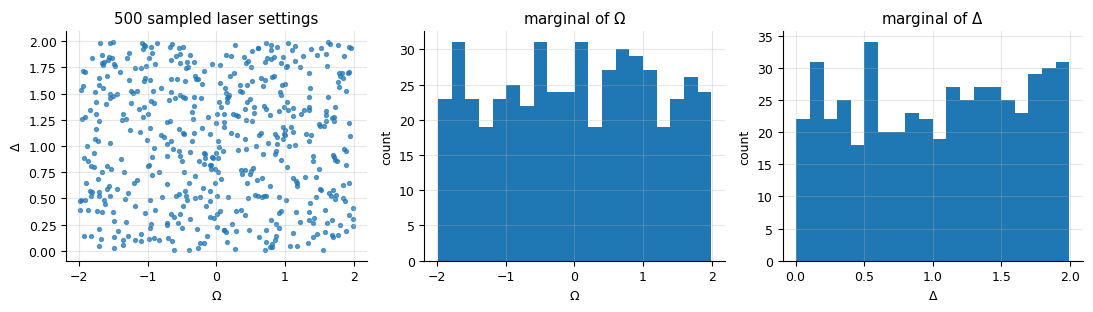

In [26]:
def plot_parameter_space(qd: QuantumData):
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
    axes[0].scatter(qd.omega, qd.delta, s=8, alpha=0.7)
    axes[0].set(xlabel=r"$\Omega$", ylabel=r"$\Delta$", title=f"{qd.n_traj} sampled laser settings")
    axes[1].hist(qd.omega, bins=20)
    axes[1].set(xlabel=r"$\Omega$", ylabel="count", title=r"marginal of $\Omega$")
    axes[2].hist(qd.delta, bins=20)
    axes[2].set(xlabel=r"$\Delta$", ylabel="count", title=r"marginal of $\Delta$")
    fig.tight_layout()
    return fig


save_fig(plot_parameter_space(QD), "01_parameter_space");

### 3.2 What the dynamics look like

Six trajectories chosen to span the parameter plane (small/large `|Omega|`, small/large `Delta`). For each one:

- top: the magnetization of every site as a function of time (site index on the vertical axis);
- bottom: an edge site, a central site, a nearest-neighbour correlation and the longest-range correlation.

The README anticipates three qualitative regimes (regular oscillations, fast relaxation, almost frozen dynamics). This figure shows where they are, and which time scales the input window has to resolve.

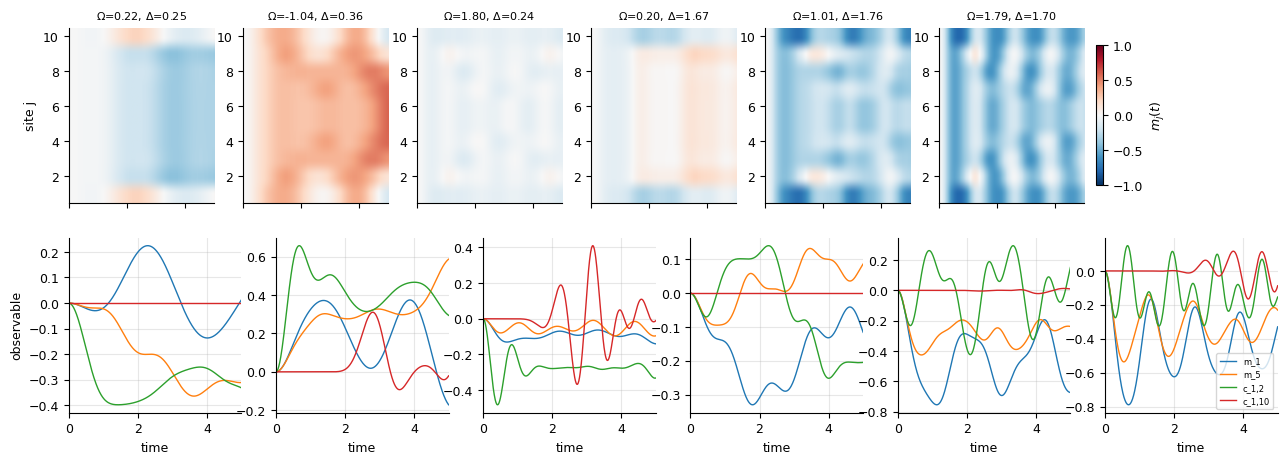

In [27]:
def pick_spread_trajectories(qd: QuantumData, n: int = 6) -> np.ndarray:
    """Trajectories closest to a regular grid of targets in the (|Omega|, Delta) plane."""
    targets = [(o, d) for d in (0.3, 1.7) for o in (0.2, 1.0, 1.8)][:n]
    pts = np.stack([np.abs(qd.omega), qd.delta], axis=1)
    return np.array([int(np.argmin(((pts - np.array(tg)) ** 2).sum(1))) for tg in targets])


def plot_example_trajectories(qd: QuantumData, idx: np.ndarray):
    spec, n = qd.spec, qd.spec.n_sites
    lines = {"m_1": 0, f"m_{n // 2}": n // 2 - 1, "c_1,2": n, f"c_1,{n}": n + n - 2}
    fig, axes = plt.subplots(2, len(idx), figsize=(2.6 * len(idx), 5), sharex=True)
    for col, k in enumerate(idx):
        im = axes[0, col].imshow(qd.X[k][:, spec.mag_idx].T, aspect="auto", origin="lower", cmap="RdBu_r",
                                 vmin=-1, vmax=1, extent=[qd.time[0], qd.time[-1], 0.5, n + 0.5])
        axes[0, col].set_title(rf"$\Omega$={qd.omega[k]:.2f}, $\Delta$={qd.delta[k]:.2f}", fontsize=8)
        axes[0, col].grid(False)
        for name, f in lines.items():
            axes[1, col].plot(qd.time, qd.X[k][:, f], lw=1, label=name)
        axes[1, col].set_xlabel("time")
    axes[0, 0].set_ylabel("site j")
    axes[1, 0].set_ylabel("observable")
    axes[1, -1].legend(fontsize=6, loc="best")
    fig.colorbar(im, ax=axes[0, :], shrink=0.8, label=r"$m_j(t)$", pad=0.01)
    return fig


save_fig(plot_example_trajectories(QD, pick_spread_trajectories(QD)), "02_example_trajectories");

### 3.3 Dynamical activity map and scale of the two feature groups

Two summaries that will be reused when interpreting the errors:

- **Dynamical activity** of a trajectory: the temporal standard deviation of its magnetizations, averaged over sites. Close to zero means "frozen", large means strong oscillations. Plotted over `(Omega, Delta)` it gives a map of the dynamical regimes, to be compared later with the map of the test error (Section 10).
- **Scale of magnetizations vs correlations.** An averaged MAE is dominated by the group with the largest amplitude. The histogram shows whether the two groups live on comparable scales, and justifies reporting them separately.

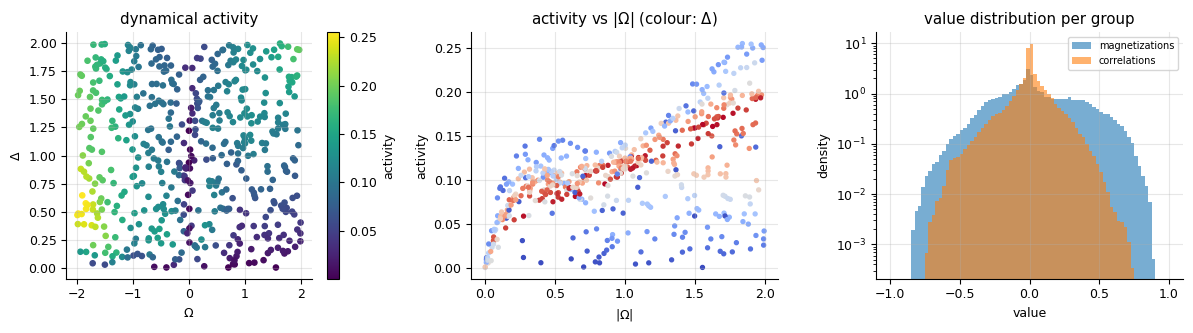

std of magnetizations: 0.2815 | std of correlations: 0.1381


In [28]:
def dynamical_activity(qd: QuantumData) -> np.ndarray:
    """Temporal std of the magnetizations, averaged over sites: one number per trajectory."""
    return qd.X[:, :, qd.spec.mag_idx].std(axis=1).mean(axis=1)


def plot_activity_and_scales(qd: QuantumData, activity: np.ndarray):
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
    sc = axes[0].scatter(qd.omega, qd.delta, c=activity, s=14, cmap="viridis")
    fig.colorbar(sc, ax=axes[0], label="activity")
    axes[0].set(xlabel=r"$\Omega$", ylabel=r"$\Delta$", title="dynamical activity")
    axes[1].scatter(np.abs(qd.omega), activity, s=8, c=qd.delta, cmap="coolwarm")
    axes[1].set(xlabel=r"$|\Omega|$", ylabel="activity", title=r"activity vs $|\Omega|$ (colour: $\Delta$)")
    bins = np.linspace(-1, 1, 81)
    axes[2].hist(qd.X[:, :, qd.spec.mag_idx].ravel(), bins=bins, alpha=0.6, density=True, label="magnetizations")
    axes[2].hist(qd.X[:, :, qd.spec.corr_idx].ravel(), bins=bins, alpha=0.6, density=True, label="correlations")
    axes[2].set(xlabel="value", ylabel="density", yscale="log", title="value distribution per group")
    axes[2].legend(fontsize=7)
    fig.tight_layout()
    return fig


ACTIVITY = dynamical_activity(QD)
save_fig(plot_activity_and_scales(QD, ACTIVITY), "03_activity_and_scales")
print("std of magnetizations: %.4f | std of correlations: %.4f"
      % (QD.X[:, :, SPEC.mag_idx].std(), QD.X[:, :, SPEC.corr_idx].std()))

## 4. Step 2 - Problem formulation and data pipeline

### 4.1 Splits

Three nested levels, all at the **trajectory** level, so that time steps of one trajectory never end up on both sides of a split (this would be a leak):

1. **Test set** (20%, fixed by `CFG.seed`): touched only for the final numbers. It is the same in all experiments, as the README requires for the study on `N_traj_train`.
2. **Training pool** (80%): used for cross-validation and for the final training.
3. Inside every training run, a **validation** part of the training trajectories drives early stopping and the learning-rate schedule.

The split along **time** is the forecasting task itself: the first `rho` steps are the input, the remaining ones the target.

Assumption to state in the report: as in the paper, training trajectories are supervised over their full length (input and target window). Only the test trajectories are unseen. The README sentence about "training times" can also be read more strictly (no late times at all during training); that would be a different, harder task.

In [29]:
def split_train_test(n_traj: int, test_fraction: float, seed: int) -> Tuple[np.ndarray, np.ndarray]:
    perm = np.random.default_rng(seed).permutation(n_traj)
    n_test = int(round(test_fraction * n_traj))
    return np.sort(perm[n_test:]), np.sort(perm[:n_test])


def split_train_val(idx: np.ndarray, val_fraction: float, seed: int) -> Tuple[np.ndarray, np.ndarray]:
    perm = np.random.default_rng(seed).permutation(idx)
    n_val = max(1, int(round(val_fraction * len(idx))))
    return np.sort(perm[n_val:]), np.sort(perm[:n_val])


def kfold_splits(idx: np.ndarray, k: int, seed: int) -> List[Tuple[np.ndarray, np.ndarray]]:
    folds = np.array_split(np.random.default_rng(seed).permutation(idx), k)
    return [(np.sort(np.concatenate([f for j, f in enumerate(folds) if j != i])), np.sort(folds[i]))
            for i in range(k)]


POOL_IDX, TEST_IDX = split_train_test(QD.n_traj, CFG.test_fraction, CFG.seed)
assert len(np.intersect1d(POOL_IDX, TEST_IDX)) == 0
print(f"training pool: {len(POOL_IDX)} trajectories | test: {len(TEST_IDX)} trajectories")
print(f"default time split: input {CFG.rho} steps (t < {CFG.rho * QD.dt:.2f}), "
      f"target {QD.n_points - CFG.rho} steps (t in [{CFG.rho * QD.dt:.2f}, {QD.time[-1]:.2f}])")

training pool: 400 trajectories | test: 100 trajectories
default time split: input 300 steps (t < 3.00), target 201 steps (t in [3.00, 5.00])


A quick check that pool and test set cover the parameter plane in the same way. If the test points clustered in one region, the test error would describe that region only.

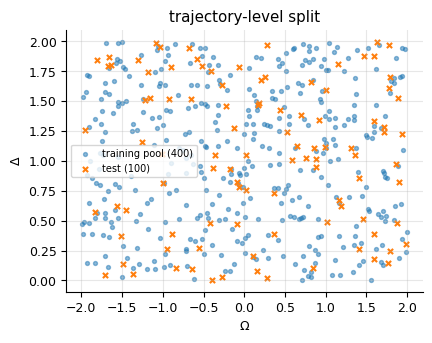

In [30]:
def plot_split(qd: QuantumData, pool_idx: np.ndarray, test_idx: np.ndarray):
    fig, ax = plt.subplots(figsize=(4.6, 3.4))
    ax.scatter(qd.omega[pool_idx], qd.delta[pool_idx], s=8, alpha=0.5, label=f"training pool ({len(pool_idx)})")
    ax.scatter(qd.omega[test_idx], qd.delta[test_idx], s=14, marker="x", label=f"test ({len(test_idx)})")
    ax.set(xlabel=r"$\Omega$", ylabel=r"$\Delta$", title="trajectory-level split")
    ax.legend(fontsize=7)
    return fig


save_fig(plot_split(QD, POOL_IDX, TEST_IDX), "04_split");

### 4.2 Scaling and windows

- `MinMaxScaler3D` maps each feature to `[0, 1]`, as in the paper. It is **fitted on the training trajectories only** and then applied to validation and test data. Fitting it on everything would leak test statistics into training.
- `make_windows` cuts each trajectory into `(input window, target window)`: one training sample per trajectory.
- All metrics are computed after mapping the predictions **back to physical units**.

In [31]:
class MinMaxScaler3D:
    """Feature-wise min-max scaling for arrays of shape (K, T, F)."""

    def fit(self, X: np.ndarray) -> "MinMaxScaler3D":
        flat = X.reshape(-1, X.shape[-1])
        self.min_ = flat.min(axis=0)
        span = flat.max(axis=0) - self.min_
        self.span_ = np.where(span > 1e-12, span, 1.0)
        return self

    def transform(self, X: np.ndarray) -> np.ndarray:
        return (X - self.min_) / self.span_

    def inverse_transform(self, X: np.ndarray) -> np.ndarray:
        return X * self.span_ + self.min_


def make_windows(X_scaled: np.ndarray, rho: int) -> Tuple[np.ndarray, np.ndarray]:
    """(K, T, F) -> input (K, rho, F) and target (K, T - rho, F)."""
    return X_scaled[:, :rho].astype(np.float32), X_scaled[:, rho:].astype(np.float32)

## 5. Models

Every model is wrapped in a small "forecaster" object with the same three members, so that one training function and one evaluation function serve all of them:

- `model`: the Keras model that is compiled and fitted (absent for the baselines);
- `training_inputs(x, y)`: what is fed to `model.fit` (only the autoregressive Transformer needs the targets as an extra input, for teacher forcing);
- `predict(x)`: the forecast `(K, tau, F)` given **only** the input window. Evaluation always goes through `predict`, so every model is scored in the realistic "free-running" condition.

Magnetizations and connected correlations are bounded by physics to `[-1, 1]`. `predict` therefore clips every forecast to this interval (`bounds`, set by `run_experiment` in scaled units). The same rule is applied to all models, so the comparison stays fair. For most models it changes almost nothing; inside the autoregressive rollout it also stops a wrong prediction from being fed back and amplified without limit.

### 5.1 Naive baselines

A model is useful only if it beats trivial strategies:

- **Persistence**: repeat the last observed value over the whole horizon.
- **Window mean**: repeat the mean of the last `k` observed values (a guess of the "equilibrium" value).

They have no parameters and need no training.

A third reference is not naive at all: **Ridge (closed form)**. It is the same kind of map as DLinear (one linear map from the `rho` past values of a feature to its `tau` future values, shared by all features), but solved exactly by regularised least squares with NumPy instead of being trained by gradient descent. It is not a deep-learning model and is not a competitor; it answers a diagnostic question. If DLinear is clearly worse than Ridge, DLinear is limited by its *optimisation*; if both are equally far from the truth, the limit is *linearity itself*.

In [32]:
class BaseForecaster:
    trainable = True

    def __init__(self, rho: int, tau: int, n_features: int):
        self.rho, self.tau, self.n_features = rho, tau, n_features
        self.model: Optional[keras.Model] = None
        self.bounds: Optional[Tuple[np.ndarray, np.ndarray]] = None   # physical limits, in scaled units

    def clip(self, y: np.ndarray) -> np.ndarray:
        return y if self.bounds is None else np.clip(y, self.bounds[0], self.bounds[1])

    def training_inputs(self, x: np.ndarray, y: np.ndarray):
        return x

    def predict(self, x: np.ndarray, batch_size: int = 128) -> np.ndarray:
        return self.clip(self.model.predict(x, batch_size=batch_size, verbose=0))

    @property
    def n_params(self) -> int:
        return int(self.model.count_params()) if self.model is not None else 0


class PersistenceBaseline(BaseForecaster):
    trainable = False

    def predict(self, x, batch_size: int = 128):
        return np.repeat(x[:, -1:, :], self.tau, axis=1)


class WindowMeanBaseline(BaseForecaster):
    trainable = False

    def __init__(self, rho, tau, n_features, window: int = 100):
        super().__init__(rho, tau, n_features)
        self.window = min(window, rho)

    def predict(self, x, batch_size: int = 128):
        return np.repeat(x[:, -self.window:, :].mean(axis=1, keepdims=True), self.tau, axis=1)



class RidgeBaseline(BaseForecaster):
    """Closed-form linear map (rho past values -> tau future values), shared by all features."""
    trainable = False

    def __init__(self, rho, tau, n_features, l2: float = 1e-4):
        super().__init__(rho, tau, n_features)
        self.l2 = l2

    def _design(self, x):                                    # (K, rho, F) -> (K * F, rho + 1)
        flat = x.transpose(0, 2, 1).reshape(-1, self.rho).astype(np.float64)
        return np.concatenate([flat, np.ones((len(flat), 1))], axis=1)

    def fit_closed_form(self, x, y):
        A = self._design(x)
        Y = y.transpose(0, 2, 1).reshape(-1, self.tau).astype(np.float64)
        self.W = np.linalg.solve(A.T @ A + self.l2 * np.eye(self.rho + 1), A.T @ Y)

    def predict(self, x, batch_size: int = 128):
        out = (self._design(x) @ self.W).reshape(len(x), self.n_features, self.tau).transpose(0, 2, 1)
        return self.clip(out.astype(np.float32))

    @property
    def n_params(self) -> int:
        return (self.rho + 1) * self.tau

### 5.2 DLinear (linear model)

DLinear (Zeng et al., 2023) is the linear model of the paper:

1. a moving average of width `kernel_size` splits the input into a slow **trend** and a **seasonal** remainder (`AveragePooling1D` with the edges replicated so that the length is preserved);
2. one `Dense` layer per component, without activation, maps the `rho` past values of a feature directly to its `tau` future values. The layer acts on the time axis and is shared by all 55 features;
3. the two outputs are summed.

The whole horizon is produced in a single forward pass (*direct* multi-step forecasting), so errors cannot accumulate along the horizon. The model has `2 * (rho * tau + tau)` parameters and no non-linearity at all.

In [33]:
class MovingAverage(layers.Layer):
    """Moving average along time with edge replication, so the length is preserved."""

    def __init__(self, kernel_size: int, **kwargs):
        super().__init__(**kwargs)
        self.kernel_size = kernel_size
        self.pool = layers.AveragePooling1D(pool_size=kernel_size, strides=1, padding="valid")

    def call(self, x):                                       # (B, L, F)
        front = tf.repeat(x[:, :1, :], (self.kernel_size - 1) // 2, axis=1)
        back = tf.repeat(x[:, -1:, :], self.kernel_size // 2, axis=1)
        return self.pool(tf.concat([front, x, back], axis=1))


class DLinearForecaster(BaseForecaster):
    def __init__(self, rho, tau, n_features, kernel_size: int = 7):
        super().__init__(rho, tau, n_features)

        def time_linear(z, name):                            # Dense on the time axis: (B, rho, F) -> (B, tau, F)
            z = layers.Permute((2, 1))(z)
            z = layers.Dense(tau, kernel_initializer=keras.initializers.Constant(1.0 / rho), name=name)(z)
            return layers.Permute((2, 1))(z)

        inp = keras.Input(shape=(rho, n_features), name="input_window")
        trend = MovingAverage(kernel_size, name="trend")(inp)
        seasonal = layers.Subtract(name="seasonal")([inp, trend])
        out = layers.Add(name="forecast")([time_linear(trend, "trend_linear"), time_linear(seasonal, "seasonal_linear")])
        self.model = keras.Model(inp, out, name="dlinear")

### 5.3 Transformer (non-linear model)

An encoder-decoder Transformer assembled from standard Keras layers (`MultiHeadAttention`, `LayerNormalization`, `Dense`, `Dropout`):

- the **encoder** embeds the `rho` input steps with a `Dense` layer, adds a sinusoidal positional encoding indexed by the absolute time step, and applies `num_layers` self-attention blocks;
- the **decoder** receives a sequence of `tau` states, attends to itself and to the encoder output, and returns one prediction per position.

Two decoding strategies are available through the hyperparameter `decoding`; they differ only in what the decoder is fed and in whether its self-attention is causal:

- `"autoregressive"` (the one used in the paper). Training uses *teacher forcing*: the decoder input is the true sequence shifted by one step, behind a causal mask, so position `i` predicts the state that follows the `i`-th input. At inference the true future is unknown, so `predict` runs a **rollout**: the prediction of step `i` is written into the decoder input of step `i + 1`, one step at a time. This creates a mismatch between training and inference (*exposure bias*) and lets errors accumulate over the horizon.
- `"direct"`. The decoder input is simply the last observed state repeated `tau` times, without causal mask, and the whole horizon comes out of one pass, like DLinear. Comparing the two separates the effect of the *architecture* from the effect of the *decoding strategy*.

Three choices differ from the paper and are deliberate:

- the first decoder input is the last observed state (instead of a zero vector);
- in autoregressive mode the decoder outputs the next **state** itself, not an increment to be added to the previous state. The series is sampled very finely (`dt = 0.01`): a model that adds small increments to its own previous output integrates its errors over 201 steps. A first version of this notebook did exactly that and its rollouts were ten times worse than the persistence baseline, despite an excellent teacher-forced loss;
- **noisy teacher forcing** (`teacher_noise`, autoregressive mode only): a `GaussianNoise` layer on the decoder input, active only during training. With clean teacher forcing the cheapest solution is "copy the previous state", which is useless in a rollout. The noise makes copying unreliable, pushes the decoder to use the encoder memory, and exposes the model to imperfect inputs like the ones it will produce itself. Its level was not tuned;
- in direct mode the network predicts the *change* with respect to the last observed state (a residual connection around the decoder).

The model is also much smaller than the paper's (2 layers, `d_model = 64`), for cost reasons that Section 7.1 quantifies.

In [34]:
class PositionalEncoding(layers.Layer):
    """Adds the fixed sinusoidal encoding of positions offset .. offset + length - 1."""

    def __init__(self, length: int, d_model: int, offset: int = 0, **kwargs):
        super().__init__(**kwargs)
        pos = np.arange(offset, offset + length)[:, None]
        angle = pos / np.power(10000.0, np.arange(0, d_model, 2)[None, :] / d_model)
        pe = np.zeros((length, d_model), dtype=np.float32)
        pe[:, 0::2], pe[:, 1::2] = np.sin(angle), np.cos(angle)
        self.pe = tf.constant(pe[None])

    def call(self, x):
        return x + self.pe


def attention_block(x, context, nhead: int, d_model: int, dropout: float, causal: bool = False):
    """Pre-norm attention sub-layer with residual connection. context=None means self-attention."""
    h = layers.LayerNormalization(epsilon=1e-6)(x)
    mha = layers.MultiHeadAttention(num_heads=nhead, key_dim=d_model // nhead, dropout=dropout)
    h = mha(h, h, use_causal_mask=causal) if context is None else mha(h, context)
    return layers.Add()([x, layers.Dropout(dropout)(h)])


def feed_forward_block(x, d_model: int, dim_feedforward: int, dropout: float):
    h = layers.LayerNormalization(epsilon=1e-6)(x)
    h = layers.Dense(dim_feedforward, activation="relu")(h)
    h = layers.Dense(d_model)(h)
    return layers.Add()([x, layers.Dropout(dropout)(h)])


class TransformerForecaster(BaseForecaster):
    def __init__(self, rho, tau, n_features, d_model: int = 64, nhead: int = 4, num_layers: int = 2,
                 dim_feedforward: int = 128, dropout: float = 0.1, decoding: str = "autoregressive",
                 teacher_noise: float = 0.1):
        super().__init__(rho, tau, n_features)
        if decoding not in ("autoregressive", "direct"):
            raise ValueError(decoding)
        self.decoding = decoding
        causal = decoding == "autoregressive"

        # encoder: input window -> memory
        enc_in = keras.Input(shape=(rho, n_features), name="input_window")
        h = PositionalEncoding(rho, d_model)(layers.Dense(d_model)(enc_in))
        for _ in range(num_layers):
            h = attention_block(h, None, nhead, d_model, dropout)
            h = feed_forward_block(h, d_model, dim_feedforward, dropout)
        self.encoder = keras.Model(enc_in, layers.LayerNormalization(epsilon=1e-6)(h), name="encoder")

        # decoder: (decoder input, memory) -> one prediction per position
        dec_in = keras.Input(shape=(tau, n_features), name="decoder_input")
        memory = keras.Input(shape=(rho, d_model), name="memory")
        h = PositionalEncoding(tau, d_model, offset=rho - 1)(layers.Dense(d_model)(dec_in))
        for _ in range(num_layers):
            h = attention_block(h, None, nhead, d_model, dropout, causal=causal)
            h = attention_block(h, memory, nhead, d_model, dropout)
            h = feed_forward_block(h, d_model, dim_feedforward, dropout)
        out = layers.Dense(n_features)(layers.LayerNormalization(epsilon=1e-6)(h))
        if not causal:                                       # direct: predict the change from the last observed state
            out = layers.Add()([dec_in, out])
        self.decoder = keras.Model([dec_in, memory], out, name="decoder")

        # full model used by model.fit
        full_in = keras.Input(shape=(tau, n_features), name="decoder_input")
        fed = layers.GaussianNoise(teacher_noise)(full_in) if causal and teacher_noise > 0 else full_in
        self.model = keras.Model([enc_in, full_in], self.decoder([fed, self.encoder(enc_in)]), name="transformer")
        self._decode = tf.function(lambda d, m: self.decoder([d, m], training=False))

    def _decoder_input(self, x, y=None):
        last = x[:, -1:, :]
        if self.decoding == "direct" or y is None:
            return np.repeat(last, self.tau, axis=1)
        return np.concatenate([last, y[:, :-1, :]], axis=1)            # teacher forcing: targets shifted right

    def training_inputs(self, x, y):
        return [x, self._decoder_input(x, y)]

    def predict(self, x, batch_size: int = 128):
        if self.decoding == "direct":
            return self.clip(self.model.predict([x, self._decoder_input(x)], batch_size=batch_size, verbose=0))
        out = np.zeros((len(x), self.tau, self.n_features), dtype=np.float32)
        for start in range(0, len(x), batch_size):                     # free-running rollout
            xb = x[start:start + batch_size]
            memory = tf.constant(self.encoder.predict(xb, batch_size=batch_size, verbose=0))
            dec = np.zeros((len(xb), self.tau, self.n_features), dtype=np.float32)
            dec[:, 0] = xb[:, -1]
            for i in range(self.tau):
                step = self.clip(self._decode(tf.constant(dec), memory).numpy()[:, i])
                out[start:start + len(xb), i] = step
                if i + 1 < self.tau:
                    dec[:, i + 1] = step                               # feed the prediction back
        return out

A quick correctness test of the rollout, on an untrained autoregressive Transformer. Thanks to the causal mask, the prediction at position `i` must not depend on later decoder inputs. Therefore, if the rollout output is fed back as a teacher-forcing sequence, a single pass must return the same output. If the mask or the shift were wrong, the two would differ.

In [35]:
def check_rollout_consistency(rho: int = 40, tau: int = 12, n_features: int = 6) -> float:
    seed_everything(0)
    fc = TransformerForecaster(rho, tau, n_features, d_model=16, nhead=2, num_layers=1, dim_feedforward=32)
    x = np.random.rand(3, rho, n_features).astype(np.float32)
    rolled = fc.predict(x)
    one_pass = fc.model.predict(fc.training_inputs(x, rolled), verbose=0)
    return float(np.abs(rolled - one_pass).max())


gap = check_rollout_consistency()
print(f"max |rollout - teacher-forced pass on the rollout| = {gap:.2e}")
assert gap < 1e-4, "causal masking or shifting is wrong"

max |rollout - teacher-forced pass on the rollout| = 0.00e+00


### 5.4 Model registry and hyperparameter sets

`build_model` creates any forecaster from its name and a hyperparameter dictionary. A hyperparameter set has three parts: `model` (architecture), `train` (optimisation) and `loss` (weights of the composite loss, Section 6.1).

`BASE_HP` holds the reference values (taken from the paper where possible) and `HP_GRID` the three configurations per model compared in Table 1. Each configuration changes **one aspect** with respect to the reference, so that a difference in the table can be attributed to a cause:

| Config | DLinear | Config | Transformer |
|---|---|---|---|
| D1 | reference: moving-average window 7, composite loss | T1 | reference: autoregressive, `d_model=64`, 2 layers, 4 heads |
| D2 | wider decomposition window (25) | T2 | larger network: `d_model=128`, 3 layers |
| D3 | plain MSE loss (`alpha = beta = 0`): ablation of the informed loss | T3 | direct decoding instead of autoregressive |

There is only **one training sample per trajectory**, so an epoch contains few gradient steps (320 trajectories with batch size 8 give 40 steps). This is why the batch sizes are small and the epoch limits high: with large batches the models stop long before converging.

To try other values, edit `HP_GRID`: nothing else in the notebook needs to change.

In [36]:
MODEL_REGISTRY = {
    "persistence": PersistenceBaseline,
    "window_mean": WindowMeanBaseline,
    "ridge": RidgeBaseline,
    "dlinear": DLinearForecaster,
    "transformer": TransformerForecaster,
}
MODEL_LABELS = {"persistence": "Persistence", "window_mean": "Window mean", "ridge": "Ridge (closed form)",
                "dlinear": "DLinear", "transformer": "Transformer"}
MODEL_COLORS = {"persistence": "0.6", "window_mean": "0.35", "ridge": "tab:green", "dlinear": "tab:blue", "transformer": "tab:red"}

BASE_HP = {
    "persistence": {"model": {}, "train": {}, "loss": {}},
    "window_mean": {"model": {"window": 100}, "train": {}, "loss": {}},
    "ridge": {"model": {"l2": 1e-4}, "train": {}, "loss": {}},
    "dlinear": {
        "model": {"kernel_size": 7},
        "train": {"lr": 1e-2, "weight_decay": 1e-3, "batch_size": 16, "max_epochs": 300, "patience": 20, "grad_clip": None},
        "loss": {"alpha": 0.5, "beta": 2.0},
    },
    "transformer": {
        "model": {"d_model": 64, "nhead": 4, "num_layers": 2, "dim_feedforward": 128, "dropout": 0.1,
                  "decoding": "autoregressive", "teacher_noise": 0.1},
        "train": {"lr": 1e-3, "weight_decay": 1e-3, "batch_size": 8, "max_epochs": 200, "patience": 15, "grad_clip": 1.0},
        "loss": {"alpha": 0.5, "beta": 2.0},
    },
}

HP_GRID = {
    "dlinear": {
        "D1": {},
        "D2": {"model": {"kernel_size": 25}},
        "D3": {"loss": {"alpha": 0.0, "beta": 0.0}},
    },
    "transformer": {
        "T1": {},
        "T2": {"model": {"d_model": 128, "dim_feedforward": 256, "num_layers": 3}},
        "T3": {"model": {"decoding": "direct"}},
    },
}


def make_hp(model_name: str, overrides: Optional[dict] = None) -> dict:
    """Reference hyperparameters of a model, with optional overrides per section."""
    hp = copy.deepcopy(BASE_HP[model_name])
    for section, values in (overrides or {}).items():
        hp[section].update(values)
    return hp


def describe_hp(model_name: str, overrides: dict) -> str:
    hp = make_hp(model_name, overrides)
    flat = {**hp["model"], **{k: v for k, v in hp["train"].items() if k != "grad_clip"}, **hp["loss"]}
    return ", ".join(f"{k}={v}" for k, v in flat.items())


def build_model(model_name: str, hp: dict, rho: int, tau: int, n_features: int) -> BaseForecaster:
    return MODEL_REGISTRY[model_name](rho, tau, n_features, **hp["model"])


for name in ("dlinear", "transformer"):
    for cfg_name, ov in HP_GRID[name].items():
        n_par = build_model(name, make_hp(name, ov), CFG.rho, QD.n_points - CFG.rho, SPEC.n_features).n_params
        print(f"{cfg_name} ({n_par:>9,d} parameters): {describe_hp(name, ov)}")
keras.backend.clear_session()

D1 (  121,002 parameters): kernel_size=7, lr=0.01, weight_decay=0.001, batch_size=16, max_epochs=300, patience=20, alpha=0.5, beta=2.0
D2 (  121,002 parameters): kernel_size=25, lr=0.01, weight_decay=0.001, batch_size=16, max_epochs=300, patience=20, alpha=0.5, beta=2.0
D3 (  121,002 parameters): kernel_size=7, lr=0.01, weight_decay=0.001, batch_size=16, max_epochs=300, patience=20, alpha=0.0, beta=0.0
T1 (  178,423 parameters): d_model=64, nhead=4, num_layers=2, dim_feedforward=128, dropout=0.1, decoding=autoregressive, teacher_noise=0.1, lr=0.001, weight_decay=0.001, batch_size=8, max_epochs=200, patience=15, alpha=0.5, beta=2.0
T2 (1,015,735 parameters): d_model=128, nhead=4, num_layers=3, dim_feedforward=256, dropout=0.1, decoding=autoregressive, teacher_noise=0.1, lr=0.001, weight_decay=0.001, batch_size=8, max_epochs=200, patience=15, alpha=0.5, beta=2.0
T3 (  178,423 parameters): d_model=64, nhead=4, num_layers=2, dim_feedforward=128, dropout=0.1, decoding=direct, teacher_noise=

## 6. Loss, metrics and training loop

### 6.1 Temporally informed loss

The composite loss of the paper (Eqs. 11-15), used for every trainable model:

`L = L_pos + alpha * L_dir + beta * L_sign`

- `L_pos`: mean squared error on the values;
- `L_dir`: mean squared error on the increments between consecutive steps (the discrete time derivative);
- `L_sign`: `ReLU(-dx_true * dx_pred)`, which is positive only when the predicted increment has the wrong sign.

With `alpha = beta = 0` it reduces to the plain MSE (configuration D3). It is written as a regular Keras loss function `loss(y_true, y_pred)` and is computed on scaled data.

In [37]:
def make_composite_loss(alpha: float = 0.5, beta: float = 2.0):
    def composite_loss(y_true, y_pred):
        loss = tf.reduce_mean(tf.square(y_pred - y_true))
        if alpha > 0 or beta > 0:
            d_pred = y_pred[:, 1:, :] - y_pred[:, :-1, :]
            d_true = y_true[:, 1:, :] - y_true[:, :-1, :]
            loss += alpha * tf.reduce_mean(tf.square(d_pred - d_true))
            loss += beta * tf.reduce_mean(tf.nn.relu(-d_true * d_pred))
        return loss
    return composite_loss

### 6.2 Evaluation metrics

Computed in physical units on the forecast horizon only:

- **MAE** (paper Eq. 17) and **RMSE**, which penalises large errors more;
- **Directional accuracy, DA** (paper Eq. 19): percentage of (trajectory, step, feature) triples whose predicted increment has the same sign as the true one. For the first predicted step the reference is the last observed value;
- **DA after smoothing**: the paper shows that small high-frequency ripples in the prediction can destroy the DA while leaving the MAE almost unchanged. Smoothing the *predictions* with a Savitzky-Golay filter (order 2) separates the two effects. Smoothing is a diagnostic only and never enters training.

MAE and DA answer different questions (size of the error vs direction of motion) and must be read together.

`compute_metrics` returns the global numbers and also every resolved version needed later: per feature group, per trajectory (for the `(Omega, Delta)` maps), per time step (error growth along the horizon) and per trajectory and feature (box plots).

In [38]:
def _da_matrix(y_true: np.ndarray, y_pred: np.ndarray, x_last: np.ndarray) -> np.ndarray:
    """Boolean (K, tau, F): does the predicted increment have the sign of the true one?"""
    d_true = np.diff(np.concatenate([x_last[:, None, :], y_true], axis=1), axis=1)
    d_pred = np.diff(np.concatenate([x_last[:, None, :], y_pred], axis=1), axis=1)
    return np.sign(d_true) == np.sign(d_pred)


def smooth_predictions(y_pred: np.ndarray, window: int) -> np.ndarray:
    """Savitzky-Golay smoothing (order 2) along time. The window is made odd and not longer than the horizon."""
    window = min(window, y_pred.shape[1])
    if window % 2 == 0:
        window -= 1
    return y_pred if window < 5 else savgol_filter(y_pred, window, polyorder=2, axis=1)


def compute_metrics(y_true: np.ndarray, y_pred: np.ndarray, x_last: np.ndarray, spec: FeatureSpec,
                    smooth_windows: Tuple[int, ...] = ()) -> dict:
    """y_true, y_pred: (K, tau, F) in physical units; x_last: (K, F) last observed state."""
    abs_err = np.abs(y_pred - y_true)
    sq_err = (y_pred - y_true) ** 2
    da = _da_matrix(y_true, y_pred, x_last)
    m = {
        "mae": abs_err.mean(), "rmse": math.sqrt(sq_err.mean()), "da": 100 * da.mean(),
        "mae_traj": abs_err.mean(axis=(1, 2)), "da_traj": 100 * da.mean(axis=(1, 2)),
        "mae_step": abs_err.mean(axis=(0, 2)), "mae_traj_feat": abs_err.mean(axis=1),
    }
    for g, cols in spec.groups.items():
        m[f"mae_{g}"] = abs_err[:, :, cols].mean()
        m[f"rmse_{g}"] = math.sqrt(sq_err[:, :, cols].mean())
        m[f"da_{g}"] = 100 * da[:, :, cols].mean()
        m[f"mae_traj_{g}"] = abs_err[:, :, cols].mean(axis=(1, 2))
    for w in smooth_windows:
        y_s = smooth_predictions(y_pred, w)
        da_s = _da_matrix(y_true, y_s, x_last)
        m[f"da_s{w}"] = 100 * da_s.mean()
        m[f"da_traj_s{w}"] = 100 * da_s.mean(axis=(1, 2))
        m[f"mae_s{w}"] = np.abs(y_s - y_true).mean()
    return {k: (float(v) if np.ndim(v) == 0 else v) for k, v in m.items()}

### 6.3 Training

`fit_forecaster` trains any forecaster with the standard Keras workflow:

- `model.compile` with the **AdamW** optimiser (optional gradient-norm clipping) and the composite loss;
- `model.fit` with three callbacks: **EarlyStopping** on the validation loss with `restore_best_weights=True`, **ReduceLROnPlateau** (halves the learning rate when the validation loss stalls) and a small `EpochTimer` that records the duration of each epoch, to quantify the cost.

The returned history also contains `hit_epoch_limit`: it is `True` when the best epoch is the last allowed one, i.e. the model was still improving when training was cut. Such a run has not converged, and its score is a lower bound of what the configuration can do.

For the autoregressive Transformer the validation loss monitored during training is teacher-forced, as in the paper: a rollout at every epoch would multiply the training time. This matters for the interpretation: a low teacher-forced loss does not guarantee a good rollout. For this reason **model selection and all reported metrics use the free-running forecast** (`predict`), computed once at the end of each run.

In [39]:
class EpochTimer(keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.times = []

    def on_epoch_begin(self, epoch, logs=None):
        self._t0 = time.perf_counter()

    def on_epoch_end(self, epoch, logs=None):
        self.times.append(time.perf_counter() - self._t0)


def fit_forecaster(fc: BaseForecaster, x_tr, y_tr, x_va, y_va, train_hp: dict, loss_hp: dict,
                   epoch_scale: float = 1.0, verbose: bool = False) -> dict:
    max_epochs = max(2, int(round(train_hp["max_epochs"] * epoch_scale)))
    patience = train_hp["patience"]
    optimizer = keras.optimizers.AdamW(learning_rate=train_hp["lr"], weight_decay=train_hp["weight_decay"],
                                       clipnorm=train_hp.get("grad_clip"))
    fc.model.compile(optimizer=optimizer, loss=make_composite_loss(**loss_hp))
    timer = EpochTimer()
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=max(1, patience // 3), min_lr=1e-6),
        timer,
    ]
    h = fc.model.fit(fc.training_inputs(x_tr, y_tr), y_tr,
                     validation_data=(fc.training_inputs(x_va, y_va), y_va),
                     epochs=max_epochs, batch_size=min(train_hp["batch_size"], len(x_tr)), shuffle=True,
                     callbacks=callbacks, verbose=2 if verbose else 0).history
    val = [float(v) for v in h["val_loss"]]
    return {"train_loss": [float(v) for v in h["loss"]], "val_loss": val, "epoch_time": timer.times,
            "best_epoch": int(np.argmin(val)) + 1, "best_val": float(np.min(val)), "epochs": len(val),
            "fit_time": float(sum(timer.times)),
            "hit_epoch_limit": bool(np.argmin(val) + 1 == len(val) == max_epochs)}

### 6.4 One function for every experiment

`run_experiment` is the only entry point used from here on. Given a model name, a hyperparameter set, the trajectory indices and a seed, it:

1. clears the Keras session and sets the seed;
2. fits the scaler on the training trajectories only;
3. builds the windows and the model;
4. trains with `fit_forecaster` (the naive baselines need nothing, Ridge is solved in closed form);
5. forecasts each requested evaluation set in free-running mode (clipped to the physical range), maps the predictions back to physical units and computes all metrics, recording the inference time as well.

Cross-validation, the final evaluation and the two scaling studies are all thin loops around this function, which guarantees that every number in the notebook comes from the same pipeline.

In [40]:
def run_experiment(qd: QuantumData, model_name: str, hp: dict, train_idx: np.ndarray, val_idx: np.ndarray,
                   eval_sets: Dict[str, np.ndarray], rho: int, seed: int, cfg: Config = CFG,
                   keep_preds: bool = False, verbose: bool = False) -> dict:
    keras.backend.clear_session()
    gc.collect()
    seed_everything(seed)
    tau = qd.n_points - rho
    scaler = MinMaxScaler3D().fit(qd.X[train_idx])
    fc = build_model(model_name, hp, rho, tau, qd.spec.n_features)
    ones = np.ones(qd.spec.n_features, dtype=np.float32)
    fc.bounds = (scaler.transform(-ones), scaler.transform(ones))      # physical range [-1, 1] in scaled units

    history = None
    x_tr, y_tr = make_windows(scaler.transform(qd.X[train_idx]), rho)
    if hasattr(fc, "fit_closed_form"):
        fc.fit_closed_form(x_tr, y_tr)
    if fc.trainable:
        x_va, y_va = make_windows(scaler.transform(qd.X[val_idx]), rho)
        history = fit_forecaster(fc, x_tr, y_tr, x_va, y_va, hp["train"], hp["loss"], cfg.epoch_scale, verbose)

    result = {"model": model_name, "hp": hp, "rho": rho, "tau": tau, "seed": seed, "n_train": len(train_idx),
              "n_params": fc.n_params, "history": history, "metrics": {}, "preds": {}, "predict_time": {}}
    for set_name, idx in eval_sets.items():
        x_ev, _ = make_windows(scaler.transform(qd.X[idx]), rho)
        t0 = time.perf_counter()
        y_scaled = fc.predict(x_ev)
        result["predict_time"][set_name] = time.perf_counter() - t0
        y_pred = scaler.inverse_transform(y_scaled).astype(np.float32)
        result["metrics"][set_name] = compute_metrics(qd.X[idx, rho:], y_pred, qd.X[idx, rho - 1], qd.spec,
                                                      cfg.smooth_windows)
        if keep_preds:
            result["preds"][set_name] = y_pred
    return result


def scalar_metrics(result: dict, set_name: str) -> dict:
    """Scalar metrics of one evaluation set, plus training and inference cost."""
    out = {k: v for k, v in result["metrics"][set_name].items() if np.ndim(v) == 0}
    hist = result["history"]
    out["epochs"] = hist["epochs"] if hist else 0
    out["fit_time"] = hist["fit_time"] if hist else 0.0
    out["predict_time"] = result["predict_time"].get(set_name, 0.0)
    return out

## 7. Hyperparameter exploration with cross-validation

### 7.1 Computational cost first

The guidelines ask to *quantify* the cost before deciding how large the experiments can be. This cell trains each configuration for 3 epochs on the default split and reports:

- the median duration of one epoch (training plus the validation pass);
- the time of one free-running forecast of the validation trajectories. For the autoregressive Transformer this is a rollout of `tau` decoder passes, so it is far more expensive than for the models that predict the horizon in one pass.

From these numbers it derives an **upper bound** of the total runtime of the notebook, assuming that no run stops early. If the bound is too high for your session, reduce `cv_folds`, the seeds or `study_models` in `Config`, and report the measured times as the justification.

In [41]:
def measure_cost(qd: QuantumData, model_name: str, overrides: dict, cfg: Config) -> dict:
    hp = make_hp(model_name, overrides)
    hp["train"].update(max_epochs=3, patience=99)
    probe_cfg = copy.copy(cfg)
    probe_cfg.epoch_scale = 1.0
    tr, va = split_train_val(POOL_IDX, cfg.val_fraction, cfg.seed)
    res = run_experiment(qd, model_name, hp, tr, va, {"val": va}, cfg.rho, cfg.seed, probe_cfg)
    return {"parameters": res["n_params"], "s/epoch": float(np.median(res["history"]["epoch_time"][1:])),
            "forecast [s]": res["predict_time"]["val"], "forecast trajectories": len(va)}


def projected_budget(cost: pd.DataFrame, cfg: Config) -> pd.DataFrame:
    rows = []
    for (model_name, cfg_name), c in cost.iterrows():
        epochs = max(2, round(make_hp(model_name, HP_GRID[model_name][cfg_name])["train"]["max_epochs"] * cfg.epoch_scale))
        n_runs = cfg.cv_folds
        if cfg_name == list(HP_GRID[model_name])[0]:          # final + studies, counted once per model
            n_runs += len(cfg.final_seeds)
            if model_name in cfg.study_models:
                n_runs += len(cfg.study_seeds) * (len(cfg.study_rhos) + len(cfg.study_ntrain))
        rows.append({"model": model_name, "config": cfg_name, "runs": n_runs, "max epochs": epochs,
                     "upper bound [min]": n_runs * (epochs * c["s/epoch"] + 2 * c["forecast [s]"]) / 60})
    return pd.DataFrame(rows).set_index(["model", "config"])


COST = pd.DataFrame({(m, c): measure_cost(QD, m, ov, CFG) for m in HP_GRID for c, ov in HP_GRID[m].items()}).T
COST.index.names = ["model", "config"]
BUDGET = projected_budget(COST, CFG)
COST.join(BUDGET).to_csv(TAB_DIR / "computational_cost.csv")
display(COST.join(BUDGET).round(3))
print(f"upper bound for the whole notebook on {DEVICE}: {BUDGET['upper bound [min]'].sum():.0f} min "
      "(early stopping normally makes it much shorter)")

parameters  s/epoch  forecast [s]  forecast trajectories  \
model       config                                                             
dlinear     D1        121002.0    0.239         0.219                   80.0   
            D2        121002.0    0.223         0.214                   80.0   
            D3        121002.0    0.214         0.228                   80.0   
transformer T1        178423.0    1.699         5.849                   80.0   
            T2       1015735.0    2.390         9.992                   80.0   
            T3        178423.0    1.672         0.812                   80.0   

                    runs  max epochs  upper bound [min]  
model       config                                       
dlinear     D1        33         300             39.710  
            D2         3         300              3.370  
            D3         3         300              3.235  
transformer T1        33         200            193.364  
            T2         3         200             24.900  
            T3         3         200             16.805

upper bound for the whole notebook on GPU x2 (/physical_device:GPU:0): 281 min (early stopping normally makes it much shorter)


### 7.2 K-fold cross-validation

Each configuration of `HP_GRID` is trained `cv_folds` times: the training pool is cut into K folds, the model is trained on K-1 folds and scored on the remaining one, in free-running mode and physical units. **The test set is not used here.**

Methodological note for the report: the held-out fold is also the one used for early stopping, so the cross-validation scores are slightly optimistic. The bias is the same for every configuration, so the *ranking* is fair, and the unbiased numbers are the test results of Section 8.

In [42]:
def cross_validate(qd: QuantumData, model_name: str, overrides: dict, pool_idx: np.ndarray, cfg: Config) -> List[dict]:
    hp = make_hp(model_name, overrides)
    results = []
    for fold, (tr, va) in enumerate(kfold_splits(pool_idx, cfg.cv_folds, cfg.seed)):
        results.append(run_experiment(qd, model_name, hp, tr, va, {"val": va}, cfg.rho, cfg.seed + fold, cfg))
    return results


CV_RESULTS: Dict[str, Dict[str, List[dict]]] = {}
for model_name, grid in HP_GRID.items():
    CV_RESULTS[model_name] = {}
    for cfg_name, overrides in grid.items():
        t0 = time.perf_counter()
        CV_RESULTS[model_name][cfg_name] = cross_validate(QD, model_name, overrides, POOL_IDX, CFG)
        maes = [r["metrics"]["val"]["mae"] for r in CV_RESULTS[model_name][cfg_name]]
        capped = sum(r["history"]["hit_epoch_limit"] for r in CV_RESULTS[model_name][cfg_name])
        print(f"{cfg_name}: validation MAE = {fmt_ci(maes, CFG.conf_level)}   [{time.perf_counter() - t0:.0f} s]"
              + (f"   ({capped}/{len(maes)} runs still improving at the epoch limit)" if capped else ""))

D1: validation MAE = 0.0551 ± 0.0032   [225 s]   (3/3 runs still improving at the epoch limit)
D2: validation MAE = 0.0521 ± 0.0032   [126 s]   (1/3 runs still improving at the epoch limit)
D3: validation MAE = 0.0549 ± 0.0032   [219 s]   (3/3 runs still improving at the epoch limit)
T1: validation MAE = 0.0548 ± 0.0015   [987 s]   (1/3 runs still improving at the epoch limit)
T2: validation MAE = 0.0514 ± 0.0025   [1559 s]   (2/3 runs still improving at the epoch limit)
T3: validation MAE = 0.0376 ± 0.0029   [981 s]   (1/3 runs still improving at the epoch limit)


### 7.3 Table 1 - hyperparameter configurations

The table has the layout requested in the guidelines: one column per configuration, one row per metric, **mean ± 95% confidence interval** over the folds, best value of each row in bold. The legend printed below the table lists the hyperparameters of every configuration.

`metric_table` is generic (it only needs a dictionary *column -> list of scalar-metric dictionaries*), so the same function also builds the final test table.

In [43]:
def metric_rows(cfg: Config) -> List[Tuple[str, str, Optional[str], int]]:
    """(row label, metric key, 'min'/'max'/None for the best value, digits)."""
    rows = [("MAE (all)", "mae", "min", 4), ("MAE (magnetizations)", "mae_mag", "min", 4),
            ("MAE (correlations)", "mae_corr", "min", 4), ("RMSE (all)", "rmse", "min", 4),
            ("DA raw [%]", "da", "max", 1)]
    rows += [(f"DA smoothed, w={w} [%]", f"da_s{w}", "max", 1) for w in cfg.smooth_windows]
    rows += [("epochs run", "epochs", None, 1), ("training time [s]", "fit_time", None, 1),
             ("forecast time [s]", "predict_time", None, 2)]
    return rows


def metric_table(columns: Dict[tuple, List[dict]], cfg: Config, name: str) -> pd.DataFrame:
    """Build, display (best in bold) and save a 'mean ± CI' table. Returns the plain-text version."""
    plain, html = {}, {}
    for label, key, best, digits in metric_rows(cfg):
        means = {col: mean_ci([r[key] for r in runs], cfg.conf_level)[0] for col, runs in columns.items()}
        target = None if best is None else (min if best == "min" else max)(means.values())
        plain[label] = {col: fmt_ci([r[key] for r in runs], cfg.conf_level, digits) for col, runs in columns.items()}
        html[label] = {col: (f"<b>{txt}</b>" if target is not None and means[col] == target else txt)
                       for col, txt in plain[label].items()}
    df_plain, df_html = pd.DataFrame(plain).T, pd.DataFrame(html).T
    if isinstance(next(iter(columns)), tuple):
        df_plain.columns = pd.MultiIndex.from_tuples(df_plain.columns)
        df_html.columns = pd.MultiIndex.from_tuples(df_html.columns)
    df_plain.to_csv(TAB_DIR / f"{name}.csv")
    (TAB_DIR / f"{name}.html").write_text(df_html.to_html(escape=False), encoding="utf-8")
    display(HTML(df_html.to_html(escape=False)))
    return df_plain


cv_columns = {(MODEL_LABELS[m], c): [scalar_metrics(r, "val") for r in runs]
              for m, grid in CV_RESULTS.items() for c, runs in grid.items()}
TABLE1 = metric_table(cv_columns, CFG, "table1_hyperparameters")
print(f"Values: mean ± {int(CFG.conf_level * 100)}% CI over {CFG.cv_folds} folds (validation folds, physical units).\nWhere:")
for m, grid in HP_GRID.items():
    for c, ov in grid.items():
        print(f"  - {c}: {describe_hp(m, ov)}")

Values: mean ± 95% CI over 3 folds (validation folds, physical units).
Where:
  - D1: kernel_size=7, lr=0.01, weight_decay=0.001, batch_size=16, max_epochs=300, patience=20, alpha=0.5, beta=2.0
  - D2: kernel_size=25, lr=0.01, weight_decay=0.001, batch_size=16, max_epochs=300, patience=20, alpha=0.5, beta=2.0
  - D3: kernel_size=7, lr=0.01, weight_decay=0.001, batch_size=16, max_epochs=300, patience=20, alpha=0.0, beta=0.0
  - T1: d_model=64, nhead=4, num_layers=2, dim_feedforward=128, dropout=0.1, decoding=autoregressive, teacher_noise=0.1, lr=0.001, weight_decay=0.001, batch_size=8, max_epochs=200, patience=15, alpha=0.5, beta=2.0
  - T2: d_model=128, nhead=4, num_layers=3, dim_feedforward=256, dropout=0.1, decoding=autoregressive, teacher_noise=0.1, lr=0.001, weight_decay=0.001, batch_size=8, max_epochs=200, patience=15, alpha=0.5, beta=2.0
  - T3: d_model=64, nhead=4, num_layers=2, dim_feedforward=128, dropout=0.1, decoding=direct, teacher_noise=0.1, lr=0.001, weight_decay=0.001, b

### 7.4 Model selection

For each model family the configuration with the lowest mean validation MAE is kept. With only a few folds the confidence intervals of two configurations often overlap: in that case the honest statement is that they are **not distinguishable** on this budget, and the choice between them is a tie-break rather than a finding. The cell prints whether the best and the second-best intervals overlap.

In [44]:
def select_best(cv_results: Dict[str, Dict[str, List[dict]]], cfg: Config, key: str = "mae") -> Dict[str, str]:
    best = {}
    for model_name, grid in cv_results.items():
        stats_ = {c: mean_ci([r["metrics"]["val"][key] for r in runs], cfg.conf_level) for c, runs in grid.items()}
        ranked = sorted(stats_, key=lambda c: stats_[c][0])
        best[model_name] = ranked[0]
        (m1, h1), (m2, h2) = stats_[ranked[0]], stats_[ranked[1]]
        overlap = not (m1 + np.nan_to_num(h1) < m2 - np.nan_to_num(h2))
        print(f"{MODEL_LABELS[model_name]}: best = {ranked[0]} ({m1:.4f}), runner-up = {ranked[1]} ({m2:.4f}); "
              f"intervals {'overlap -> not clearly distinguishable' if overlap else 'do not overlap'}")
    return best


BEST_CFG = select_best(CV_RESULTS, CFG)
BEST_HP = {m: make_hp(m, HP_GRID[m][c]) for m, c in BEST_CFG.items()}
BEST_HP.update({b: make_hp(b) for b in ("persistence", "window_mean", "ridge")})

DLinear: best = D2 (0.0521), runner-up = D3 (0.0549); intervals overlap -> not clearly distinguishable
Transformer: best = T3 (0.0376), runner-up = T2 (0.0514); intervals do not overlap


## 8. Final training and evaluation on the test set

The selected configuration of each model is retrained on the whole training pool (minus an internal validation part for early stopping) and evaluated **once** on the held-out test trajectories. The run is repeated with several seeds; a seed changes the weight initialisation, the batch order and the train/validation partition, so the confidence interval reflects the variability of the whole training procedure. The reference models (persistence, window mean, Ridge) have no random component and are run once.

In [45]:
def final_runs(qd: QuantumData, model_name: str, hp: dict, cfg: Config, rho: Optional[int] = None,
               pool_idx: Optional[np.ndarray] = None, seeds: Optional[Tuple[int, ...]] = None,
               keep_preds: bool = True) -> List[dict]:
    """Train on (a subset of) the pool with several seeds and evaluate on the fixed test set."""
    pool_idx = POOL_IDX if pool_idx is None else pool_idx
    seeds = cfg.final_seeds if seeds is None else seeds
    if not MODEL_REGISTRY[model_name].trainable:
        seeds = seeds[:1]
    runs = []
    for seed in seeds:
        tr, va = split_train_val(pool_idx, cfg.val_fraction, seed)
        runs.append(run_experiment(qd, model_name, hp, tr, va, {"test": TEST_IDX}, rho or cfg.rho, seed, cfg,
                                   keep_preds=keep_preds))
    return runs


MODEL_ORDER = ["persistence", "window_mean", "ridge", "dlinear", "transformer"]
FINAL: Dict[str, List[dict]] = {}
for model_name in MODEL_ORDER:
    t0 = time.perf_counter()
    FINAL[model_name] = final_runs(QD, model_name, BEST_HP[model_name], CFG)
    maes = [r["metrics"]["test"]["mae"] for r in FINAL[model_name]]
    print(f"{MODEL_LABELS[model_name]:<12s} test MAE = {fmt_ci(maes, CFG.conf_level)}   [{time.perf_counter() - t0:.0f} s]")

Persistence  test MAE = 0.0670   [4 s]
Window mean  test MAE = 0.0653   [4 s]
Ridge (closed form) test MAE = 0.0485   [4 s]
DLinear      test MAE = 0.0523 ± 0.0002   [171 s]
Transformer  test MAE = 0.0351 ± 0.0054   [930 s]


### 8.1 Table 2 - test results

Same layout as Table 1, now on the test set, with mean ± 95% CI over seeds. Things to read from it:

- do the trained models beat the two naive baselines, and by how much? (Persistence and window mean have DA close to 0 by construction, since their increments are all zero.)
- how does DLinear compare with Ridge, the exact solution of the same kind of linear map? A gap means that gradient descent has not reached the linear optimum (check the "epochs run" row and the learning curves); no gap means that the limit is linearity itself.
- is the ranking the same for magnetizations and for correlations?
- do MAE and DA tell the same story? A low MAE with a DA near 50% that rises sharply after smoothing is the signature described in the paper for DLinear: correct trend plus small high-frequency ripples.

In [46]:
final_columns = {(MODEL_LABELS[m] if m not in BEST_CFG else f"{MODEL_LABELS[m]} ({BEST_CFG[m]})"):
                 [scalar_metrics(r, "test") for r in FINAL[m]] for m in MODEL_ORDER}
TABLE2 = metric_table(final_columns, CFG, "table2_test_results")
print(f"Values: mean ± {int(CFG.conf_level * 100)}% CI over {len(CFG.final_seeds)} seeds, {len(TEST_IDX)} test trajectories.")

,Persistence,Window mean,Ridge (closed form),DLinear (D2),Transformer (T3)
MAE (all),0.0670,0.0653,0.0485,0.0523 ± 0.0002,0.0351 ± 0.0054
MAE (magnetizations),0.0920,0.0916,0.0619,0.0686 ± 0.0005,0.0468 ± 0.0078
MAE (correlations),0.0615,0.0595,0.0455,0.0487 ± 0.0001,0.0325 ± 0.0048
RMSE (all),0.1047,0.0960,0.0748,0.0782 ± 0.0002,0.0520 ± 0.0072
DA raw [%],0.2,0.2,61.4,58.1 ± 0.3,59.4 ± 2.6
"DA smoothed, w=11 [%]",0.2,0.2,61.4,58.1 ± 0.4,62.3 ± 3.0
"DA smoothed, w=21 [%]",0.2,0.2,61.3,58.1 ± 0.3,64.7 ± 3.4
"DA smoothed, w=41 [%]",0.2,0.2,60.8,57.9 ± 0.4,67.0 ± 3.7
epochs run,0.0,0.0,0.0,220.3 ± 342.8,171.0 ± 37.3
training time [s],0.0,0.0,0.0,52.2 ± 79.5,303.8 ± 66.7


Values: mean ± 95% CI over 3 seeds, 100 test trajectories.


### 8.2 Learning curves

Training and validation loss of the final runs (one line per seed), as recorded by `model.fit`. The dots mark the epoch whose weights were restored by early stopping. A validation curve that turns upward while the training curve keeps decreasing indicates overfitting.

For the autoregressive Transformer both curves are teacher-forced, so they describe one-step prediction only. Its free-running quality is what Table 2 and the following figures show; a large difference between a very low loss here and a poor MAE there is the exposure bias.

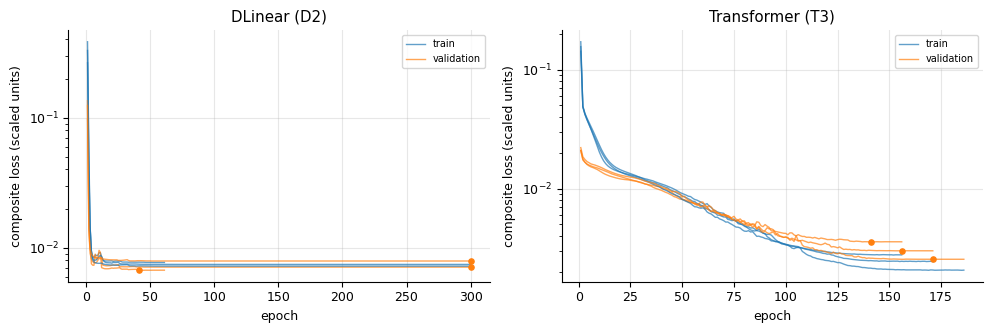

In [47]:
def plot_learning_curves(final: Dict[str, List[dict]], models: List[str]):
    fig, axes = plt.subplots(1, len(models), figsize=(5 * len(models), 3.4))
    for ax, m in zip(np.atleast_1d(axes), models):
        for i, r in enumerate(final[m]):
            h = r["history"]
            ep = np.arange(1, h["epochs"] + 1)
            ax.plot(ep, h["train_loss"], color="tab:blue", alpha=0.7, lw=1, label="train" if i == 0 else None)
            ax.plot(ep, h["val_loss"], color="tab:orange", alpha=0.7, lw=1, label="validation" if i == 0 else None)
            ax.scatter([h["best_epoch"]], [h["best_val"]], color="tab:orange", s=14, zorder=3)
        ax.set(yscale="log", xlabel="epoch", ylabel="composite loss (scaled units)",
               title=f"{MODEL_LABELS[m]} ({BEST_CFG[m]})")
        ax.legend(fontsize=7)
    fig.tight_layout()
    return fig


save_fig(plot_learning_curves(FINAL, ["dlinear", "transformer"]), "05_learning_curves");

## 9. Step 3 - Looking inside the results

Helper functions used by all the figures of this section: seed-averaged metric arrays, and the choice of three representative test trajectories (best, typical, worst), selected as in the paper through the *joint* MAE of the two models so that neither model is favoured.

In [48]:
def seed_mean(runs: List[dict], key: str, set_name: str = "test") -> np.ndarray:
    return np.mean([r["metrics"][set_name][key] for r in runs], axis=0)


def seed_stack(runs: List[dict], key: str, set_name: str = "test") -> np.ndarray:
    return np.stack([r["metrics"][set_name][key] for r in runs], axis=0)


def representative_trajectories(final: Dict[str, List[dict]], models=("dlinear", "transformer")) -> Dict[str, int]:
    """Positions (inside the test set) of the best / typical / worst trajectory by joint MAE."""
    joint = np.mean([seed_mean(final[m], "mae_traj") for m in models], axis=0)
    return {"best": int(joint.argmin()), "typical": int(np.abs(joint - joint.mean()).argmin()),
            "worst": int(joint.argmax())}


REPR = representative_trajectories(FINAL)
for tag, pos in REPR.items():
    k = TEST_IDX[pos]
    print(f"{tag:<8s}: trajectory {k}  (Omega = {QD.omega[k]:+.3f}, Delta = {QD.delta[k]:.3f})")

best    : trajectory 46  (Omega = +0.023, Delta = 1.053)
typical : trajectory 454  (Omega = +1.159, Delta = 0.670)
worst   : trajectory 239  (Omega = -1.511, Delta = 0.369)


### 9.1 Predicted vs true dynamics

Rows: best, typical and worst test trajectory. Columns: an edge magnetization, a central magnetization, a nearest-neighbour correlation and the longest-range correlation. Grey is the observed input window, black the true future, colours the forecasts (first seed). The vertical line marks the end of the input window.

This is the most direct check that the numbers of Table 2 mean what we think: look at whether a model follows the oscillations, damps them, drifts, or adds ripples.

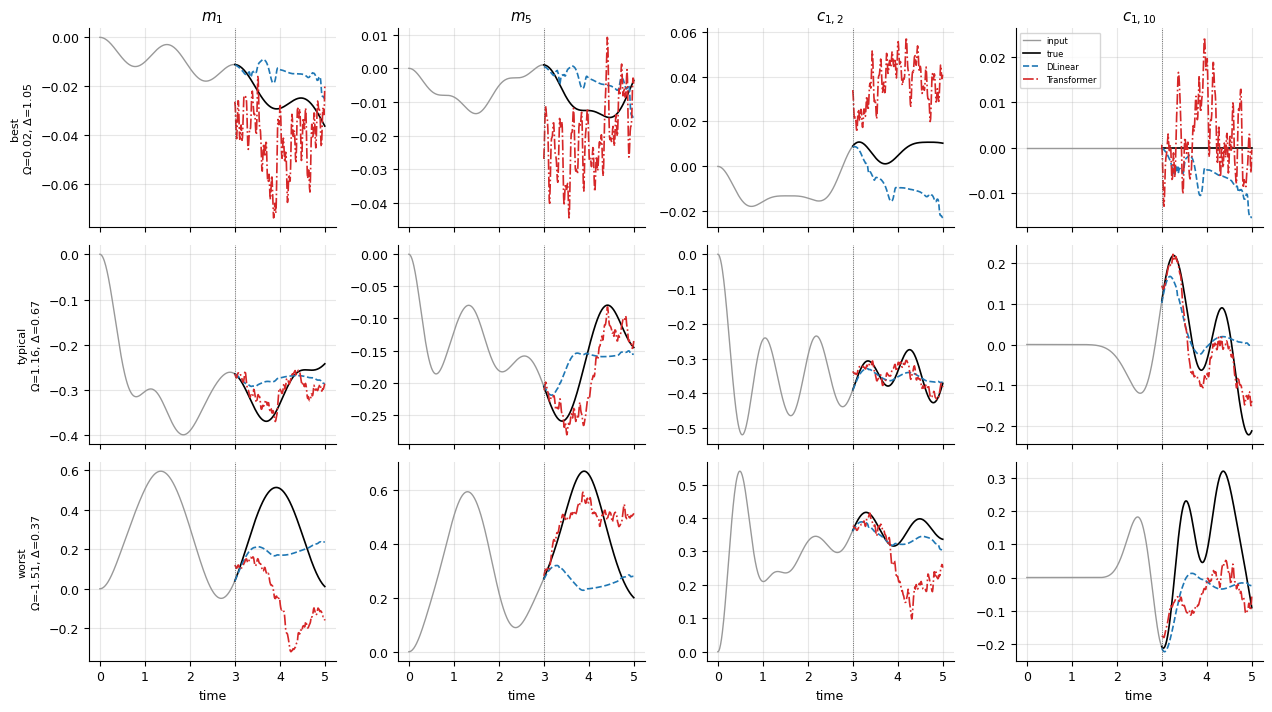

In [49]:
def plot_forecast_examples(qd: QuantumData, final: Dict[str, List[dict]], repr_pos: Dict[str, int], rho: int,
                           models=("dlinear", "transformer")):
    n = qd.spec.n_sites
    feats = {"$m_1$": 0, f"$m_{{{n // 2}}}$": n // 2 - 1, "$c_{1,2}$": n, f"$c_{{1,{n}}}$": n + n - 2}
    fig, axes = plt.subplots(len(repr_pos), len(feats), figsize=(3.2 * len(feats), 2.4 * len(repr_pos)), sharex=True)
    styles = {"dlinear": "--", "transformer": "-."}
    for row, (tag, pos) in enumerate(repr_pos.items()):
        k = TEST_IDX[pos]
        for col, (fname, f) in enumerate(feats.items()):
            ax = axes[row, col]
            ax.plot(qd.time[:rho], qd.X[k, :rho, f], color="0.6", lw=1, label="input")
            ax.plot(qd.time[rho:], qd.X[k, rho:, f], color="k", lw=1.2, label="true")
            for m in models:
                ax.plot(qd.time[rho:], final[m][0]["preds"]["test"][pos, :, f], styles.get(m, ":"),
                        color=MODEL_COLORS[m], lw=1.2, label=MODEL_LABELS[m])
            ax.axvline(qd.time[rho], color="0.3", lw=0.6, ls=":")
            if row == 0:
                ax.set_title(fname)
            if col == 0:
                ax.set_ylabel(f"{tag}\n" + rf"$\Omega$={qd.omega[k]:.2f}, $\Delta$={qd.delta[k]:.2f}", fontsize=8)
            if row == len(repr_pos) - 1:
                ax.set_xlabel("time")
    axes[0, -1].legend(fontsize=6, loc="best")
    fig.tight_layout()
    return fig


save_fig(plot_forecast_examples(QD, FINAL, REPR, CFG.rho), "06_forecast_examples");

### 9.2 Absolute error resolved in time and site

Counterpart of Fig. 3 of the paper: absolute error `|prediction - truth|` of the ten magnetizations (horizontal axis) along the forecast horizon (vertical axis), for the same three trajectories. All panels share one colour scale. It shows whether the error is localised in time (a missed revival), in space (edges vs centre of the chain) or spread everywhere.

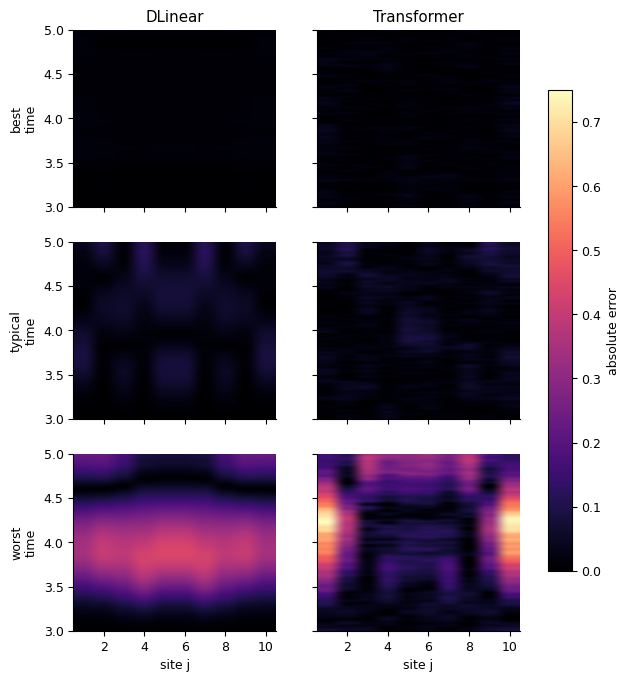

In [50]:
def plot_error_heatmaps(qd: QuantumData, final: Dict[str, List[dict]], repr_pos: Dict[str, int], rho: int,
                        models=("dlinear", "transformer")):
    cols = qd.spec.mag_idx
    errs = {(tag, m): np.abs(final[m][0]["preds"]["test"][pos][:, cols] - qd.X[TEST_IDX[pos], rho:][:, cols])
            for tag, pos in repr_pos.items() for m in models}
    vmax = max(e.max() for e in errs.values())
    fig, axes = plt.subplots(len(repr_pos), len(models), figsize=(3.6 * len(models), 2.6 * len(repr_pos)),
                             sharex=True, sharey=True)
    for row, tag in enumerate(repr_pos):
        for col, m in enumerate(models):
            ax = axes[row, col]
            im = ax.imshow(errs[(tag, m)], aspect="auto", origin="lower", cmap="magma", vmin=0, vmax=vmax,
                           extent=[0.5, len(cols) + 0.5, qd.time[rho], qd.time[-1]])
            ax.grid(False)
            if row == 0:
                ax.set_title(MODEL_LABELS[m])
            if col == 0:
                ax.set_ylabel(f"{tag}\ntime")
            if row == len(repr_pos) - 1:
                ax.set_xlabel("site j")
    fig.colorbar(im, ax=axes, shrink=0.8, label="absolute error")
    return fig


save_fig(plot_error_heatmaps(QD, FINAL, REPR, CFG.rho), "07_error_heatmaps");

### 9.3 Error growth along the forecast horizon

Counterpart of Fig. 4 of the paper: MAE at each prediction time, averaged over test trajectories and features (line: mean over seeds, band: 95% CI). The persistence baseline is the reference: a model only adds value where its curve is below it.

What to look for: a curve that saturates (bounded error) versus one that keeps growing or oscillates with increasing amplitude, which is the signature of error accumulation in autoregressive decoding.

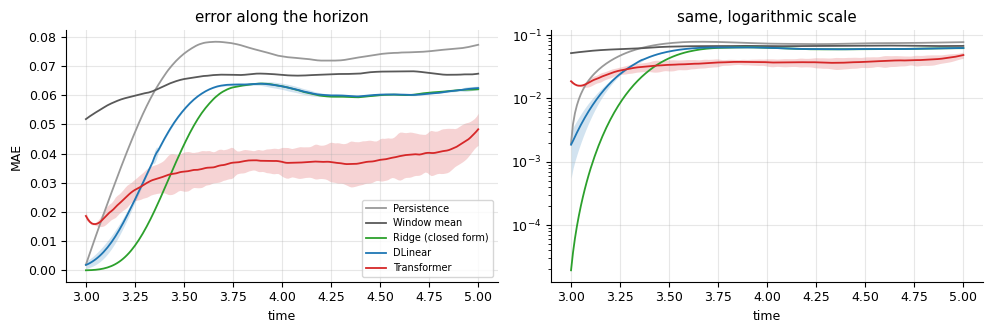

In [51]:
def plot_horizon_error(qd: QuantumData, final: Dict[str, List[dict]], rho: int, cfg: Config):
    t = qd.time[rho:]
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharex=True)
    for m in MODEL_ORDER:
        stack = seed_stack(final[m], "mae_step")
        mean = stack.mean(axis=0)
        for ax in axes:
            ax.plot(t, mean, color=MODEL_COLORS[m], lw=1.3, label=MODEL_LABELS[m])
            if stack.shape[0] > 1:
                half = stats.t.ppf(0.5 + cfg.conf_level / 2, stack.shape[0] - 1) * stack.std(axis=0, ddof=1) / math.sqrt(stack.shape[0])
                ax.fill_between(t, mean - half, mean + half, color=MODEL_COLORS[m], alpha=0.2, lw=0)
    axes[0].set(xlabel="time", ylabel="MAE", title="error along the horizon")
    axes[1].set(xlabel="time", yscale="log", title="same, logarithmic scale")
    axes[0].legend(fontsize=7)
    fig.tight_layout()
    return fig


save_fig(plot_horizon_error(QD, FINAL, CFG.rho, CFG), "08_horizon_error");

### 9.4 Error per observable

The guidelines ask to evaluate variables separately to discover biases.

- Top row (counterpart of Fig. 5 of the paper): distribution over test trajectories of the MAE of each magnetization. Box: quartiles, line: median, triangle: mean. A mean well above the median means that a few trajectories dominate the error.
- Bottom row: MAE of the correlations grouped by distance `|i - j|`, to see whether short-range and long-range correlations are equally predictable.

Because of the mirror symmetry verified in Section 2.3, sites `j` and `N+1-j` carry the same signal, so the profile over sites should be symmetric. An asymmetric profile would point to a problem in the model or in the pipeline.

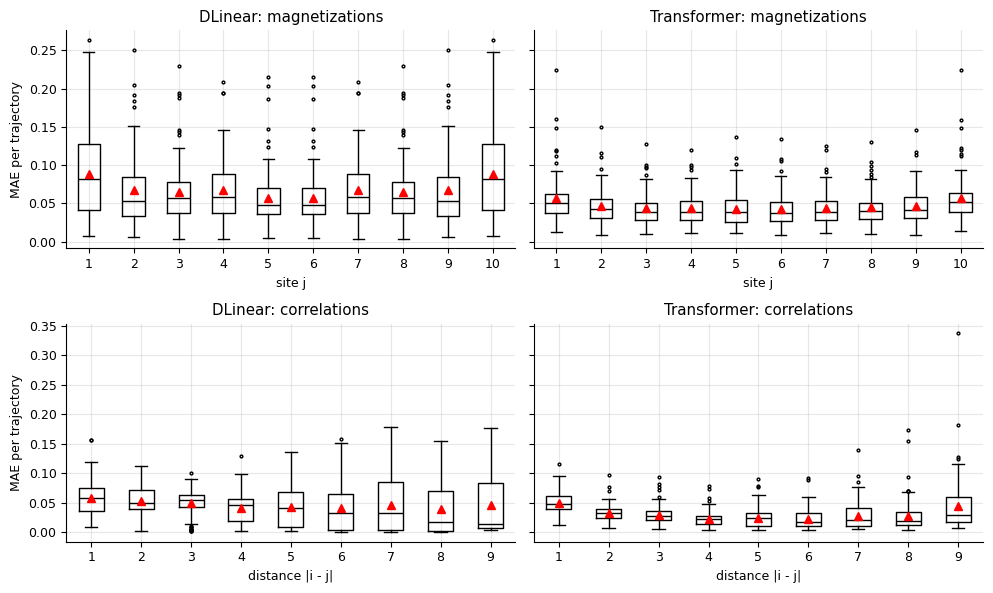

In [52]:
def plot_feature_errors(qd: QuantumData, final: Dict[str, List[dict]], models=("dlinear", "transformer")):
    spec = qd.spec
    fig, axes = plt.subplots(2, len(models), figsize=(5 * len(models), 6), sharey="row")
    dists = np.arange(1, spec.n_sites)
    for col, m in enumerate(models):
        e = seed_mean(final[m], "mae_traj_feat")                         # (K_test, F)
        axes[0, col].boxplot([e[:, f] for f in spec.mag_idx], showmeans=True, flierprops={"markersize": 2},
                             medianprops={"color": "k"}, meanprops={"markerfacecolor": "red", "markeredgecolor": "red"})
        axes[0, col].set(title=f"{MODEL_LABELS[m]}: magnetizations", xlabel="site j")
        by_dist = [e[:, spec.corr_idx[spec.pair_dist == d]].mean(axis=1) for d in dists]
        axes[1, col].boxplot(by_dist, showmeans=True, flierprops={"markersize": 2},
                             medianprops={"color": "k"}, meanprops={"markerfacecolor": "red", "markeredgecolor": "red"})
        axes[1, col].set(title=f"{MODEL_LABELS[m]}: correlations", xlabel="distance |i - j|")
    axes[0, 0].set_ylabel("MAE per trajectory")
    axes[1, 0].set_ylabel("MAE per trajectory")
    fig.tight_layout()
    return fig


save_fig(plot_feature_errors(QD, FINAL), "09_feature_errors");

### 9.5 Directional accuracy and smoothing

DA and MAE of each model as a function of the Savitzky-Golay window applied to its predictions (`raw` = no smoothing). Interpretation, following the paper:

- DA rises strongly with moderate smoothing while the MAE stays flat: the model has the right trend, and its low raw DA comes from small high-frequency ripples;
- DA does not improve: the model is wrong about the trend itself;
- DA falls again for very large windows: the filter is removing real dynamics.

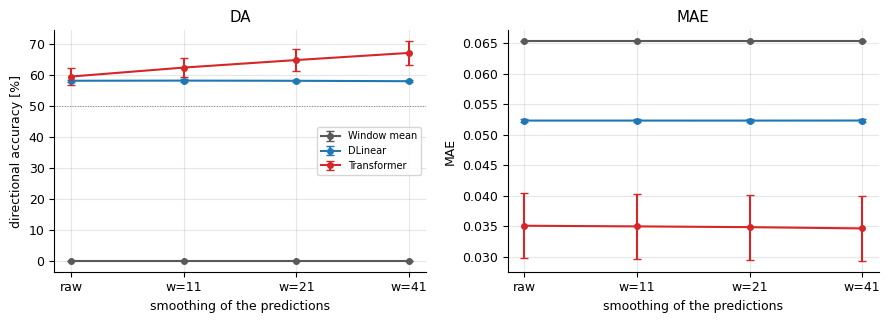

In [53]:
def plot_da_vs_smoothing(final: Dict[str, List[dict]], cfg: Config, models=("window_mean", "dlinear", "transformer")):
    labels = ["raw"] + [f"w={w}" for w in cfg.smooth_windows]
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.3))
    for m in models:
        for ax, keys in zip(axes, (["da"] + [f"da_s{w}" for w in cfg.smooth_windows],
                                   ["mae"] + [f"mae_s{w}" for w in cfg.smooth_windows])):
            vals = np.array([[r["metrics"]["test"][k] for k in keys] for r in final[m]])
            cis = np.nan_to_num([mean_ci(vals[:, i], cfg.conf_level)[1] for i in range(len(keys))])
            ax.errorbar(range(len(keys)), vals.mean(axis=0), yerr=cis, marker="o", ms=4, capsize=3,
                        color=MODEL_COLORS[m], label=MODEL_LABELS[m])
            ax.set_xticks(range(len(keys)))
            ax.set_xticklabels(labels)
    axes[0].axhline(50, color="0.5", lw=0.7, ls=":")
    axes[0].set(xlabel="smoothing of the predictions", ylabel="directional accuracy [%]", title="DA")
    axes[1].set(xlabel="smoothing of the predictions", ylabel="MAE", title="MAE")
    axes[0].legend(fontsize=7)
    fig.tight_layout()
    return fig


save_fig(plot_da_vs_smoothing(FINAL, CFG), "10_da_vs_smoothing");

## 10. Task: how does the performance depend on (Omega, Delta)?

Each test trajectory is one point of the parameter plane, coloured by its own error (averaged over horizon, features and seeds). Rows are models; columns are the MAE on all features, on magnetizations, on correlations, and the DA after moderate smoothing. Colour scales are shared within a column, so the two models can be compared directly.

To read together with the activity map of Section 3.3: the regions that are hard to forecast can then be related to a dynamical regime (strongly oscillating, relaxing, frozen).

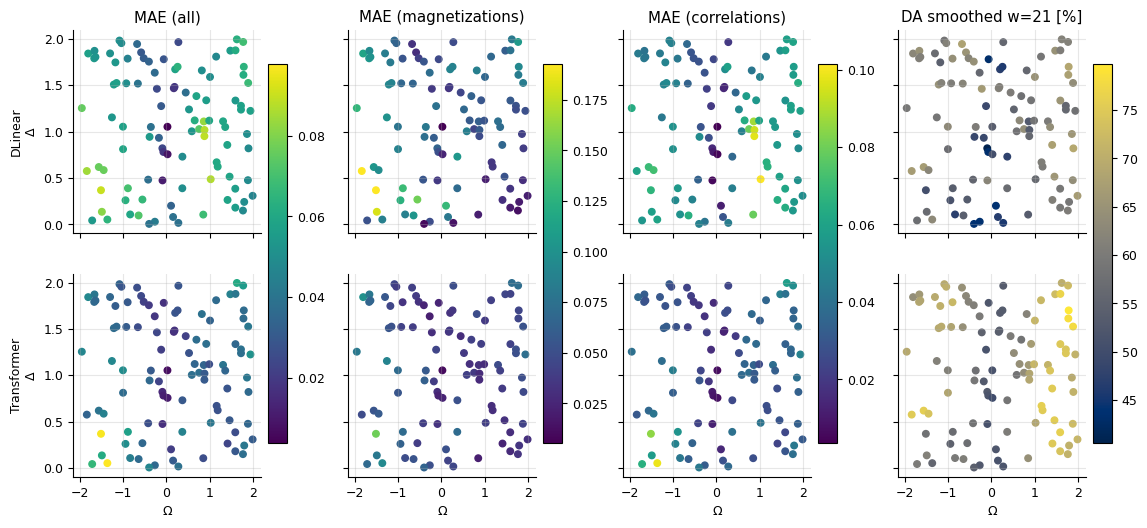

In [54]:
def plot_error_maps(qd: QuantumData, final: Dict[str, List[dict]], cfg: Config, models=("dlinear", "transformer")):
    w = cfg.smooth_windows[len(cfg.smooth_windows) // 2]
    panels = [("mae_traj", "MAE (all)", "viridis"), ("mae_traj_mag", "MAE (magnetizations)", "viridis"),
              ("mae_traj_corr", "MAE (correlations)", "viridis"), (f"da_traj_s{w}", f"DA smoothed w={w} [%]", "cividis")]
    om, de = qd.omega[TEST_IDX], qd.delta[TEST_IDX]
    data = {(m, key): seed_mean(final[m], key) for m in models for key, _, _ in panels}
    fig, axes = plt.subplots(len(models), len(panels), figsize=(3.4 * len(panels), 2.9 * len(models)),
                             sharex=True, sharey=True)
    for col, (key, title, cmap) in enumerate(panels):
        vmin = min(data[(m, key)].min() for m in models)
        vmax = max(data[(m, key)].max() for m in models)
        for row, m in enumerate(models):
            ax = axes[row, col]
            sc = ax.scatter(om, de, c=data[(m, key)], s=22, cmap=cmap, vmin=vmin, vmax=vmax)
            if row == 0:
                ax.set_title(title)
            if col == 0:
                ax.set_ylabel(f"{MODEL_LABELS[m]}\n" + r"$\Delta$")
            if row == len(models) - 1:
                ax.set_xlabel(r"$\Omega$")
        fig.colorbar(sc, ax=axes[:, col], shrink=0.85, pad=0.03)
    return fig


save_fig(plot_error_maps(QD, FINAL, CFG), "11_error_vs_parameters");

### 10.1 Which physical quantity explains the error?

The same per-trajectory errors plotted against three candidate explanatory variables: `|Omega|` (drive strength), `Delta` (detuning) and the dynamical activity of the trajectory. The table reports Spearman rank correlations with their p-values (a rank correlation does not assume a linear relation), and the last table lists the hardest test trajectories of each model.

A caveat for the interpretation: an absolute error is naturally larger where the signal moves more. The persistence baseline is included for this reason, since it shows how much of the pattern is simply "more motion, more error" and how much is specific to a model.

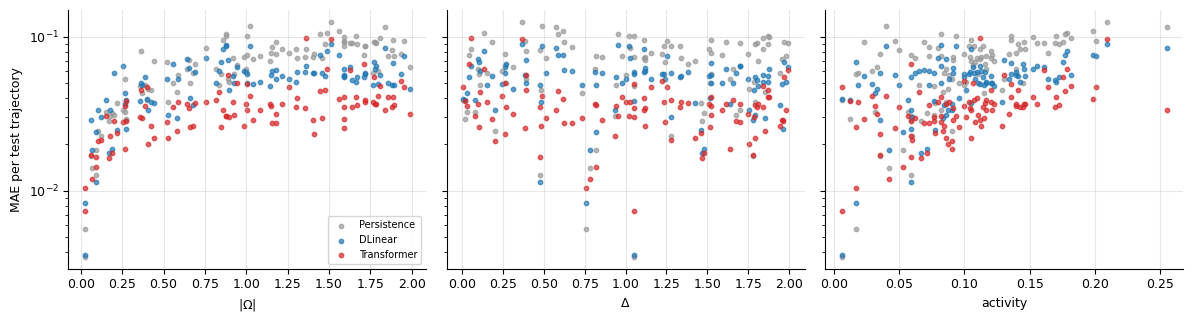

spearman                         p-value                        
model     DLinear Persistence Transformer DLinear Persistence Transformer
driver                                                                   
Delta      -0.157       0.087      -0.119   0.119       0.389       0.239
activity    0.467       0.582       0.497   0.000       0.000       0.000
|Omega|     0.519       0.782       0.603   0.000       0.000       0.000

,model,trajectory,Omega,Delta,activity,MAE
0,DLinear,239,-1.5107,0.3687,0.2090,0.0901
1,DLinear,252,0.8759,0.9515,0.0817,0.0883
2,DLinear,225,0.8782,1.0183,0.0937,0.0873
3,DLinear,453,1.0217,0.4871,0.0399,0.0870
4,DLinear,53,-1.8376,0.5756,0.2552,0.0845
5,Transformer,265,-1.3638,0.0524,0.1116,0.0978
6,Transformer,239,-1.5107,0.3687,0.2090,0.0971
7,Transformer,245,-1.7142,0.0427,0.0592,0.0662
8,Transformer,280,-1.4903,0.1360,0.1786,0.0614
9,Transformer,107,1.6256,1.9953,0.1609,0.0606


In [55]:
def error_drivers(qd: QuantumData, final: Dict[str, List[dict]], activity: np.ndarray,
                  models=("persistence", "dlinear", "transformer")):
    drivers = {r"$|\Omega|$": np.abs(qd.omega[TEST_IDX]), r"$\Delta$": qd.delta[TEST_IDX], "activity": activity[TEST_IDX]}
    fig, axes = plt.subplots(1, len(drivers), figsize=(4 * len(drivers), 3.3), sharey=True)
    rows = []
    for ax, (dname, x) in zip(axes, drivers.items()):
        for m in models:
            e = seed_mean(final[m], "mae_traj")
            ax.scatter(x, e, s=10, alpha=0.7, color=MODEL_COLORS[m], label=MODEL_LABELS[m])
            rho_s, p = stats.spearmanr(x, e)
            rows.append({"model": MODEL_LABELS[m], "driver": dname.replace("$", "").replace("\\", ""),
                         "spearman": rho_s, "p-value": p})
        ax.set(xlabel=dname, yscale="log")
    axes[0].set_ylabel("MAE per test trajectory")
    axes[0].legend(fontsize=7)
    fig.tight_layout()
    return fig, pd.DataFrame(rows).pivot(index="driver", columns="model", values=["spearman", "p-value"])


def hardest_trajectories(qd: QuantumData, final: Dict[str, List[dict]], activity: np.ndarray, n: int = 5,
                         models=("dlinear", "transformer")) -> pd.DataFrame:
    frames = []
    for m in models:
        e = seed_mean(final[m], "mae_traj")
        top = np.argsort(e)[::-1][:n]
        frames.append(pd.DataFrame({"model": MODEL_LABELS[m], "trajectory": TEST_IDX[top], "Omega": qd.omega[TEST_IDX[top]],
                                    "Delta": qd.delta[TEST_IDX[top]], "activity": activity[TEST_IDX[top]], "MAE": e[top]}))
    return pd.concat(frames, ignore_index=True)


fig, DRIVERS = error_drivers(QD, FINAL, ACTIVITY)
save_fig(fig, "12_error_drivers")
DRIVERS.to_csv(TAB_DIR / "error_drivers_spearman.csv")
display(DRIVERS.round(3))
HARDEST = hardest_trajectories(QD, FINAL, ACTIVITY)
HARDEST.to_csv(TAB_DIR / "hardest_trajectories.csv", index=False)
display(HARDEST.round(4))

## 11. Task: how does the performance change with the number of training time steps?

The number of trajectories is fixed (whole pool) and `rho = N_points_train` varies. Changing `rho` changes two things at once: the model sees a longer history **and** has a shorter horizon left to predict. To avoid confusing the two, three errors are reported for each `rho`:

- **remaining horizon**: MAE over all the times after `rho` (the quantity defined in the README; horizons of different length);
- **common final window**: MAE over the last time steps only, which are in the horizon of every `rho`. Same physical times for all, so this isolates the benefit of observing more history;
- **first steps**: MAE over the same number of steps right after `rho`. Same lead time for all.

`run_study` is shared with the next section: it loops over a list of settings, calls `final_runs` and collects one row per (model, setting, seed).

In [ ]:
def run_study(qd: QuantumData, cfg: Config, settings: List[dict], common: int = 0) -> pd.DataFrame:
    """settings: list of {'value': x, 'rho': int, 'pool': indices or None (per-seed nested subsets of size 'n')}."""
    rows = []
    for model_name in ("persistence", "ridge") + tuple(cfg.study_models):
        t0 = time.perf_counter()
        for s in settings:
            for seed in (cfg.study_seeds if MODEL_REGISTRY[model_name].trainable else cfg.study_seeds[:1]):
                pool = POOL_IDX if s.get("n") is None else np.random.default_rng(seed).permutation(POOL_IDX)[:s["n"]]
                r = final_runs(qd, model_name, BEST_HP[model_name], cfg, rho=s["rho"], pool_idx=pool,
                               seeds=(seed,), keep_preds=False)[0]
                m = r["metrics"]["test"]
                row = {"model": model_name, "value": s["value"], "seed": seed, "mae": m["mae"], "mae_mag": m["mae_mag"],
                       "mae_corr": m["mae_corr"], "da": m["da"], "fit_time": scalar_metrics(r, "test")["fit_time"]}
                if common:
                    row.update(mae_common=float(m["mae_step"][-common:].mean()), mae_first=float(m["mae_step"][:common].mean()))
                rows.append(row)
        print(f"{MODEL_LABELS[model_name]:<12s} done in {time.perf_counter() - t0:.0f} s")
    return pd.DataFrame(rows)


def study_table(df: pd.DataFrame, metrics: Dict[str, str], cfg: Config, name: str) -> pd.DataFrame:
    table = df.groupby(["model", "value"]).agg(**{label: (key, lambda v: fmt_ci(v, cfg.conf_level))
                                                   for key, label in metrics.items()})
    table.to_csv(TAB_DIR / f"{name}.csv")
    return table


def plot_study(df: pd.DataFrame, metrics: Dict[str, str], xlabel: str, cfg: Config, logx: bool = False):
    fig, axes = plt.subplots(1, len(metrics), figsize=(4 * len(metrics), 3.3))
    for ax, (key, label) in zip(np.atleast_1d(axes), metrics.items()):
        for m in df["model"].unique():
            g = df[df.model == m].groupby("value")[key]
            xs = np.array(sorted(g.groups))
            mean = np.array([mean_ci(g.get_group(x), cfg.conf_level)[0] for x in xs])
            half = np.nan_to_num([mean_ci(g.get_group(x), cfg.conf_level)[1] for x in xs])
            ax.errorbar(xs, mean, yerr=half, marker="o", ms=4, capsize=3, color=MODEL_COLORS[m], label=MODEL_LABELS[m])
        ax.set(xlabel=xlabel, ylabel=label, yscale="log")
        if logx:
            ax.set_xscale("log")
            ax.set_xticks(sorted(df["value"].unique()))
            ax.set_xticklabels(sorted(df["value"].unique()))
    np.atleast_1d(axes)[0].legend(fontsize=7)
    fig.tight_layout()
    return fig


valid_rhos = [r for r in CFG.study_rhos if 20 <= r <= QD.n_points - 20]
COMMON = QD.n_points - max(valid_rhos)
TIME_STUDY = run_study(QD, CFG, [{"value": r, "rho": r} for r in valid_rhos], common=COMMON)
TIME_STUDY.to_csv(TAB_DIR / "study_training_times_raw.csv", index=False)

Results of the study on `N_points_train`: table with mean ± 95% CI over seeds, and one panel per error definition (logarithmic vertical axis, error bars = 95% CI).

Expected behaviour to compare with: more history should help, at least until the input window covers the slowest time scale of the dynamics. If the error on the common final window stops improving beyond some `rho`, the extra history carries no additional information for that model.

In [ ]:
TIME_METRICS = {"mae": "MAE, remaining horizon", "mae_common": f"MAE, last {COMMON} steps (common window)",
                "mae_first": f"MAE, first {COMMON} steps after rho"}
display(study_table(TIME_STUDY, TIME_METRICS, CFG, "study_training_times"))
save_fig(plot_study(TIME_STUDY, TIME_METRICS, r"training time steps $N_{points\_train}$ ($\rho$)", CFG), "13_study_training_times");

## 12. Task: how does the performance change with the number of training trajectories?

`rho` is fixed and the number of available trajectories varies, always evaluating on the **same test set**. For each seed the subsets are nested (the 25 trajectories are contained in the 50, and so on), so that along a curve the only thing that changes is the amount of data. The given number includes the validation part used for early stopping.

This is a learning curve in the statistical sense. A curve that is still decreasing at the largest size says that more simulations would help; a flat curve says the model is limited by its capacity or by the task, not by the data. Models with few parameters are expected to saturate earlier and to be better in the small-data regime.

In [ ]:
valid_n = [n for n in CFG.study_ntrain if 10 <= n <= len(POOL_IDX)]
NTRAIN_STUDY = run_study(QD, CFG, [{"value": n, "rho": CFG.rho, "n": n} for n in valid_n])
NTRAIN_STUDY.to_csv(TAB_DIR / "study_training_trajectories_raw.csv", index=False)

NTRAIN_METRICS = {"mae": "MAE (all)", "mae_mag": "MAE (magnetizations)", "mae_corr": "MAE (correlations)"}
display(study_table(NTRAIN_STUDY, NTRAIN_METRICS, CFG, "study_training_trajectories"))
save_fig(plot_study(NTRAIN_STUDY, NTRAIN_METRICS, r"training trajectories $N_{traj\_train}$", CFG, logx=True),
         "14_study_training_trajectories");

## 13. Summary and saved artefacts

The cell below gathers the headline numbers in one place and stores everything needed to rebuild tables and figures without retraining (`results.pkl`), together with the configuration used.

All figures are in `outputs/figures` (JPEG, 300 dpi) and all tables in `outputs/tables` (CSV, plus HTML for the two main tables).

In [ ]:
def summarise(final: Dict[str, List[dict]], cfg: Config) -> pd.DataFrame:
    rows = []
    for m in MODEL_ORDER:
        s = [scalar_metrics(r, "test") for r in final[m]]
        rows.append({"model": MODEL_LABELS[m], "config": BEST_CFG.get(m, "-"), "parameters": final[m][0]["n_params"],
                     "test MAE": fmt_ci([x["mae"] for x in s], cfg.conf_level),
                     "test DA [%]": fmt_ci([x["da"] for x in s], cfg.conf_level, 1),
                     "training time [s]": fmt_ci([x["fit_time"] for x in s], cfg.conf_level, 1)})
    return pd.DataFrame(rows).set_index("model")


SUMMARY = summarise(FINAL, CFG)
SUMMARY.to_csv(TAB_DIR / "summary.csv")
display(SUMMARY)

with open(Path(CFG.out_dir) / "results.pkl", "wb") as fh:
    pickle.dump({"config": asdict(CFG), "profile": PROFILE, "hp_grid": HP_GRID, "best_cfg": BEST_CFG,
                 "cv": CV_RESULTS, "final": FINAL, "time_study": TIME_STUDY, "ntrain_study": NTRAIN_STUDY,
                 "test_idx": TEST_IDX, "pool_idx": POOL_IDX}, fh)
print("saved:", sorted(p.name for p in FIG_DIR.iterdir()), sorted(p.name for p in TAB_DIR.iterdir()), sep="\n")

### What to write in the report

The notebook produces the evidence; the conclusions have to be read from the outputs of *your* run. A checklist of the questions each output answers:

1. **Data (Section 2).** Which checks gave a warning, and what was done about it. State the discrepancy in the README (`N = 20` in the text, `N = 10` in the files) and the redundancy implied by the mirror symmetry.
2. **Linear vs Transformer (Tables 1-2, Figs. 05-10).** Is the difference between the two larger than their confidence intervals? Does it hold for both feature groups? Does direct decoding (T3) close the gap with DLinear? If it does, the weakness is in autoregressive decoding rather than in attention. Compare with the paper, where DLinear was uniformly accurate and the autoregressive Transformer degraded in part of the parameter space.
3. **Dependence on (Omega, Delta) (Figs. 11-12).** Where are the hard regions, do they coincide for the two models, and do they match the high-activity region of Fig. 03?
4. **Training time steps (Fig. 13)** and **training trajectories (Fig. 14).** Where do the curves saturate, and which model needs less data?
5. **Cost (Section 7.1).** Report parameters, seconds per epoch and forecast time next to the accuracy: a model that is slightly better but far more expensive is a different trade-off.

**Limitations to acknowledge**

- Few folds and seeds give wide confidence intervals; overlapping intervals mean "no evidence of a difference".
- The validation fold drives early stopping, so the cross-validation scores are slightly optimistic (the test scores are not affected).
- Early stopping of the autoregressive Transformer monitors the teacher-forced loss (as in the paper), which is only a proxy of the rollout quality. The noise level of the teacher forcing (`teacher_noise`) was not tuned.
- The Transformer is small and its hyperparameter search is limited to three configurations, for the cost reasons quantified in Section 7.1. A negative result for the Transformer therefore holds for this budget, not for the architecture in general.
- Training trajectories are supervised at late times as well (paper protocol). Forecasting late times without ever having seen them in training would be a different experiment.
- The models never receive `(Omega, Delta)` explicitly: they must infer the regime from the input window. Feeding the two parameters as extra inputs is a natural extension.